<div style="display: flex; flex-direction: column; background-color: RGB(36,172,189); text-align: center;">
    <h1 style="margin: 0; padding: 30px 30px 10px 30px; color:#fff">Classifiez automatiquement des informations Turn over RH Technova</h1>
</div>

## Contexte
Vous êtes mandaté en tant que Consultant Data Scientist par le département RH de votre client. Il s’agit de l'ESN TechNova Partners, spécialisée dans le conseil en transformation digitale et la vente d’applications en SaaS.

Ils font face à un turnover plus élevé que d'habitude et ils souhaitent identifier les causes racines potentielles derrière ces démissions.

## Objectifs du projet :
1. identifier les causes racines des démissions
2. analyse des données pour avoir une vision objective et exhaustive de la situation

Pour le responsable SIRH TechNova

### Etapes :
1. Une  analyse exploratoire et un nettoyage des données
2. Une modélisation avec sa feature engineering
3. Mise en place d'un modèle de prédiction des démissions avec classification supervisée

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Import des modules</h3>
</div>

In [1]:
import pandas as pd
# Pour forcer l'affichage des graphiques matplot dans les cellules du notebook :
%matplotlib inline 
import matplotlib.pyplot as plt
import seaborn as sns 
from data_profiling import ProfileReport  # Pour l'EDA fg_data_profiling (pip install fg-data-profiling)
import numpy as np
import sklearn
from scipy.stats import chi2_contingency

d:\Formation AI Engineer OpenClassRooms\Projet 4 Classifiez automatiquement des informations\.venv-P4-OC-AI\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Pas de limite pour afficher les colonnes du df au lieu des 20 par défaut
pd.set_option('display.max_columns', None)
# Idem pour les lignes en sortie (ascenseur activé dans les paramètres) et son option pour remettre par défaut
# pd.set_option('display.max_rows', None)
# pd.reset_option('display.max_rows')

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Import des fichiers</h3>
</div>

In [3]:
sirh = pd.read_csv("extrait_sirh.csv", sep=',', decimal='.')
eval = pd.read_csv("extrait_eval.csv", sep=',', decimal='.')
sondage = pd.read_csv("extrait_sondage.csv", sep=',', decimal='.')

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Analyse Exploratoire et Nettoyage</h3>
</div>

<div style="border: 1px solid RGB(36,172,189);" >
<h4 style="margin: auto; padding: 12px; color: RGB(36,172,189); ">SIRH</h4>
</div>

In [4]:
# On regarde le contenu de sirh
sirh.head()

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2


In [5]:
profile_sirh = ProfileReport(
    sirh, 
    title=f"Profiling Report - sirh", 
    explorative=True
    )
    
# Génère 1 fichier HTML avec le rapport d'EDA
profile_sirh.to_file(f"rapport_sirh.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 39.95it/s]


Remarques concernant le fichier SIRH :

nombre_heures_travailless = 80 pour tous

forte corrélation entre années dans le poste et années dans l'entreprise

Pas d'incohérence constatée

id_employee unique pour chaque employé

In [6]:
# nettoyage des données
# On supprime les colonnes sans variance (ne différentie pas les individus)
sirh_clean = sirh.drop(columns=['nombre_heures_travailless']).copy()

In [7]:
sirh_clean.head()

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,6,2,2


<div style="border: 1px solid RGB(36,172,189);" >
<h4 style="margin: auto; padding: 12px; color: RGB(36,172,189); ">EVAL</h4>
</div>

In [8]:
# On regarde le contenu de eval
eval.head()

,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %
3,4,3,1,3,3,3,E_5,3,Oui,11 %
4,1,3,1,2,4,3,E_7,3,Non,12 %


In [9]:
profile_eval = ProfileReport(
    eval, 
    title=f"Profiling Report - eval", 
    explorative=True
    )
    
# Génère 1 fichier HTML avec le rapport d'EDA
profile_eval.to_file(f"rapport_eval.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 413.84it/s]


Remarques concernant le fichier EVAL :

eval_number unique pour chaque évaluation en texte

forte corrélation entre augementation_salaire_precedente et note_evaluation_actuelle (3 ou 4)

augementation_salaire_precedente est en object du à la présence du symbole % dans les valeurs, il faudra le convertir en numerique pour l'analyse

Pas d'incohérence constatée

In [10]:
# nettoyage des données
# On prépare la colonne clé pour la jointure (eval_number au format E_1 à la place de 1) et on la renomme pour la jointure
eval_cle_corrigee = eval.copy()
eval_cle_corrigee['id_employee'] = eval_cle_corrigee['eval_number'].apply(lambda x: int(str(x).replace('E_', '')))

# On passe en numéque la colonne augementation_salaire_precedente pour l'analyse on en profite pour corriger le titre de la colonne
eval_cle_corrigee['augmentation_salaire_precedente_(%)'] = eval_cle_corrigee['augementation_salaire_precedente'].apply(lambda x: int(str(x).replace('%', '')))
eval_clean = eval_cle_corrigee.copy()

# On supprime la colonne corrigée
eval_clean = eval_clean.drop(columns=['augementation_salaire_precedente', 'eval_number']).copy()

In [11]:
eval_clean.head()

,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,id_employee,augmentation_salaire_precedente_(%)
0,2,3,2,4,1,1,3,Oui,1,11
1,3,2,2,2,4,3,4,Non,2,23
2,4,2,1,3,2,3,3,Oui,4,15
3,4,3,1,3,3,3,3,Oui,5,11
4,1,3,1,2,4,3,3,Non,7,12


<div style="border: 1px solid RGB(36,172,189);" >
<h4 style="margin: auto; padding: 12px; color: RGB(36,172,189); ">Sondage</h4>
</div>

In [12]:
# On regarde le contenu de sondage
sondage.head()

,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2


In [13]:
profile_sondage = ProfileReport(
    sondage, 
    title=f"Profiling Report - sondage", 
    explorative=True
    )
    
# Génère 1 fichier HTML avec le rapport d'EDA
profile_sondage.to_file(f"rapport_sondage.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 75.72it/s]


Remarques concernant le fichier Sondage :

code_sondage unique pour chaque évaluation en nombre

nombre_employee_sous_responsabilite = 1 pour tous

ayant_enfants = True pour tous

forte corrélation positive entre annes_sous_responsable_actuel et annees_depuis_la_derniere_promotion

Faible corrélation positive entre a_quitte_l_entreprise et nombre_participation_pee + frequence_deplacement + annes_sous_responsable_actuel

In [14]:
# nettoyage des données
# On supprime les colonnes sans variance
sondage_clean = sondage.drop(columns=['nombre_employee_sous_responsabilite', 'ayant_enfants']).copy()
# On renomme la clé pour la jointure
sondage_clean = sondage_clean.rename(columns={'code_sondage': 'id_employee'})

In [15]:
sondage_clean.head()

,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,id_employee,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,2,Infra & Cloud,Occasionnel,0,5
1,Non,1,3,2,8,1,Infra & Cloud,Frequent,1,7
2,Oui,0,3,4,2,2,Autre,Occasionnel,0,0
3,Non,0,3,5,3,4,Infra & Cloud,Frequent,3,0
4,Non,1,3,7,2,1,Transformation Digitale,Occasionnel,2,2


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Jointure des 3 DataFrames</h3>
</div>

In [16]:
# Jointure des 3 DataFrames sur la cle repérée a priori 
df_jointure = sirh_clean.merge(
    eval_clean, on="id_employee", how="inner").merge(
    sondage_clean, on="id_employee", how="inner")

In [17]:
# On se rappelle les dimensions des df de base
print("Dimensions de sirh_clean : ", sirh_clean.shape)
print("Dimensions de eval_clean : ", eval_clean.shape)
print("Dimensions de sondage_clean : ", sondage_clean.shape)

Dimensions de sirh_clean :  (1470, 11)
Dimensions de eval_clean :  (1470, 10)
Dimensions de sondage_clean :  (1470, 10)


In [18]:
# On vérifie si la jointure est bien réalisée
print("Dimensions de df_jointure attendues de 1470 lignes et 30 colonnes : ", df_jointure.shape)

Dimensions de df_jointure attendues de 1470 lignes et 30 colonnes :  (1470, 29)


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Anonymisation / RGPD</h3>
</div>

In [19]:
# Avec la jointure réalisée, on peut supprimer l'identifiant de l'employé pour le RGPD et non utile pour l'analyse
df_jointure_clean = df_jointure.copy()
df_jointure_clean = df_jointure_clean.drop(columns=['id_employee']).copy()


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">EDA jointure - stats descriptives et analyse bivariée</h3>
</div>

In [20]:
# On visualise notre DF de jointure
df_jointure_clean.head()

,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augmentation_salaire_precedente_(%),a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,8,6,4,2,3,2,4,1,1,3,Oui,11,Oui,0,0,1,2,Infra & Cloud,Occasionnel,0,5
1,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,10,10,7,3,2,2,2,4,3,4,Non,23,Non,1,3,8,1,Infra & Cloud,Frequent,1,7
2,37,M,2090,Célibataire,Consulting,Consultant,6,7,0,0,4,2,1,3,2,3,3,Oui,15,Oui,0,3,2,2,Autre,Occasionnel,0,0
3,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,8,8,7,4,3,1,3,3,3,3,Oui,11,Non,0,3,3,4,Infra & Cloud,Frequent,3,0
4,27,M,3468,Marié(e),Consulting,Consultant,9,6,2,2,1,3,1,2,4,3,3,Non,12,Non,1,3,2,1,Transformation Digitale,Occasionnel,2,2


In [21]:
# Distribution globale de la variable cible
effectifs_cible = df_jointure_clean["a_quitte_l_entreprise"].value_counts()
pourcentages_cible = (
    df_jointure_clean["a_quitte_l_entreprise"].value_counts(normalize=True)
    * 100
)

recap_cible = pd.DataFrame(
    {"Effectif": effectifs_cible, "Pourcentage (%)": pourcentages_cible.round(2)}
)
print("Distribution de la variable cible :")
print(recap_cible)

Distribution de la variable cible :
                       Effectif  Pourcentage (%)
a_quitte_l_entreprise                           
Non                        1233            83.88
Oui                         237            16.12


In [22]:
# Comparaison des moyennes des variables quantitatives selon le statut de depart
# On selectionne uniquement les colonnes numeriques pour le calcul
colonnes_num = df_jointure_clean.select_dtypes(include=["number"]).columns

# groupby regroupe les donnees selon la colonne cible
# agg("mean") calcule la moyenne de chaque colonne numerique pour chaque groupe
comparaison_moyennes = (
    df_jointure_clean.groupby("a_quitte_l_entreprise")[colonnes_num]
    .mean()
    .T.round(2)
)

# On renomme les colonnes pour une lecture directe
comparaison_moyennes.columns = ["Moyenne_en_poste", "Moyenne_Demissionnaires"]

# Calcul de l'ecart relatif pour identifier les plus gros contrastes
comparaison_moyennes["Ecart_Relatif_(%)"] = (
    (
        comparaison_moyennes["Moyenne_Demissionnaires"]
        - comparaison_moyennes["Moyenne_en_poste"]
    )
    / comparaison_moyennes["Moyenne_en_poste"]
    * 100
).round(1)

print("\nComparaison des moyennes selon le depart :")
print(
    comparaison_moyennes.sort_values(
        by="Ecart_Relatif_(%)", key=abs, ascending=False
    )
)


Comparaison des moyennes selon le depart :
                                           Moyenne_en_poste  \
nombre_participation_pee                               0.85   
annees_dans_le_poste_actuel                            4.48   
annes_sous_responsable_actuel                          4.37   
annee_experience_totale                               11.86   
annees_dans_l_entreprise                               7.37   
revenu_mensuel                                      6832.74   
niveau_hierarchique_poste                              2.15   
distance_domicile_travail                              8.92   
annees_depuis_la_derniere_promotion                    2.23   
satisfaction_employee_environnement                    2.77   
satisfaction_employee_nature_travail                   2.78   
nombre_experiences_precedentes                         2.65   
age                                                   37.56   
note_evaluation_precedente                             2.77   
nb_formatio

In [23]:
# Sélection des 8 variables numériques qui présentent le plus fort écart entre les deux groupes
top_8_contrastes = (
    comparaison_moyennes.sort_values(
        by="Ecart_Relatif_(%)", key=abs, ascending=False
    )
    .drop(index=["cible_depart"], errors="ignore")
    .head(8)
)

print("Top 8 des écarts moyens les plus marqués :")
print(top_8_contrastes)

Top 8 des écarts moyens les plus marqués :
                               Moyenne_en_poste  Moyenne_Demissionnaires  \
nombre_participation_pee                   0.85                     0.53   
annees_dans_le_poste_actuel                4.48                     2.90   
annes_sous_responsable_actuel              4.37                     2.85   
annee_experience_totale                   11.86                     8.24   
annees_dans_l_entreprise                   7.37                     5.13   
revenu_mensuel                          6832.74                  4787.09   
niveau_hierarchique_poste                  2.15                     1.64   
distance_domicile_travail                  8.92                    10.63   

                               Ecart_Relatif_(%)  
nombre_participation_pee                   -37.6  
annees_dans_le_poste_actuel                -35.3  
annes_sous_responsable_actuel              -34.8  
annee_experience_totale                    -30.5  
annees_dans_l_ent

(-0.6, 15.6)

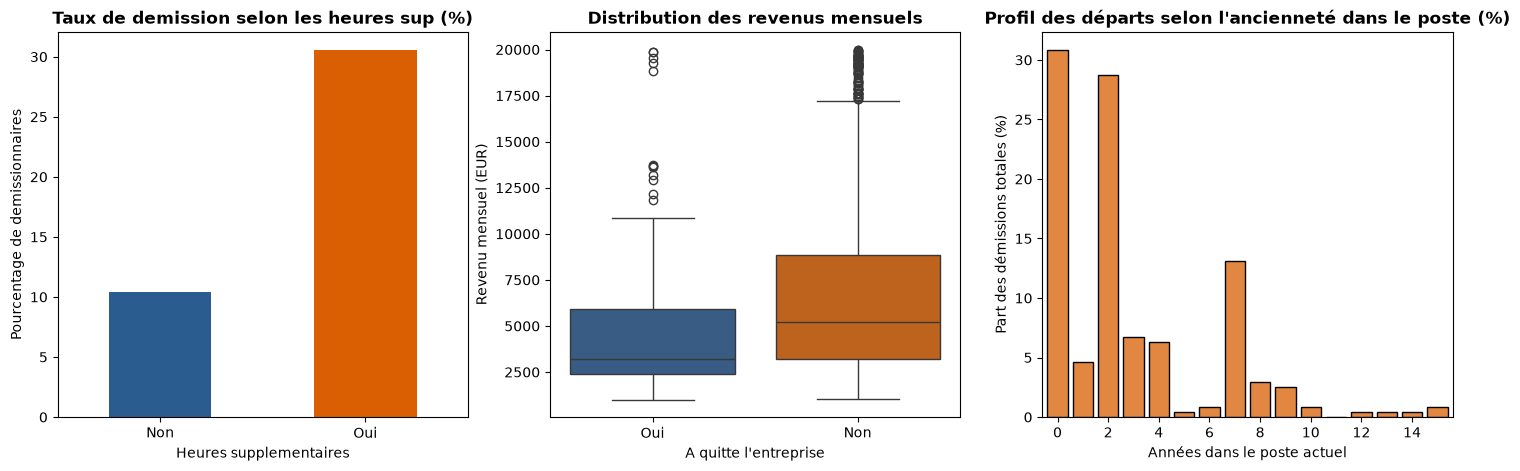

In [24]:
# Creation d'une grille de trois sous-graphiques alignes horizontalement
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Graphique 1 : Heures supplementaires (Variable qualitative vs Cible)
# pd.crosstab calcule la table de contingence
# normalize='index' calcule le pourcentage de departs a l'interieur de chaque statut (Oui/Non)
tab_hs = (
    pd.crosstab(
        df_jointure_clean["heure_supplementaires"],
        df_jointure_clean["a_quitte_l_entreprise"],
        normalize="index",
    )
    * 100
)

tab_hs["Oui"].plot(kind="bar", ax=axes[0], color=["#2b5c8f", "#d95f02"])
axes[0].set_title(
    "Taux de demission selon les heures sup (%)", fontweight="bold"
)
axes[0].set_ylabel("Pourcentage de demissionnaires")
axes[0].set_xlabel("Heures supplementaires")
axes[0].tick_params(axis="x", rotation=0)

# Graphique 2 : Revenu mensuel (Variable quantitative vs Cible)
# sns.boxplot montre la mediane, les quartiles et les valeurs extremes pour chaque groupe
sns.boxplot(
    data=df_jointure_clean,
    x="a_quitte_l_entreprise",
    y="revenu_mensuel",
    hue="a_quitte_l_entreprise",
    palette=["#2b5c8f", "#d95f02"],
    legend=False,  # Supprime la legende devenue inutile puisque l'axe x indique deja les categories
    ax=axes[1],
)
axes[1].set_title("Distribution des revenus mensuels", fontweight="bold")
axes[1].set_xlabel("A quitte l'entreprise")
axes[1].set_ylabel("Revenu mensuel (EUR)")

# Graphique 3 : Repartition des démissions par annees dans le poste actuel (en pourcentage)
# (Quantitative discrète vs Qualitative - Histogramme)
demissions = df_jointure_clean[
    df_jointure_clean["a_quitte_l_entreprise"] == "Oui"
]
max_annees = int(demissions["annees_dans_le_poste_actuel"].max())

sns.histplot(
    data=demissions,
    x="annees_dans_le_poste_actuel",
    stat="percent",  # Calcule le pourcentage sur le total des départs (somme = 100%)
    discrete=True,  # Une barre par année entière
    color="#d95f02",  # Couleur d'alerte pour les démissions
    shrink=0.8,  # Espacement net entre chaque barre annuelle
    ax=axes[2],
)

axes[2].set_title(
    "Profil des départs selon l'ancienneté dans le poste (%)", fontweight="bold"
)
axes[2].set_xlabel("Années dans le poste actuel")
axes[2].set_ylabel("Part des démissions totales (%)")

# Graduations entières de 2 en 2 pour conserver une échelle lisible
axes[2].set_xticks(range(0, max_annees + 1, 2))
axes[2].set_xlim(-0.6, max_annees + 0.6)

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Analyse multivariée</h3>
</div>

In [25]:
# Pour commencer on fait une cartographie des types et détection des valeurs extrêmes pour le choix des visu multivariées 
# (quali, quanti, ordinales, discretes, continues, extreme, asymétrie, etc.)

# Cartographie des variables
colonnes_toutes = [
    col for col in df_jointure_clean.columns if col != "a_quitte_l_entreprise"
]

quanti_candidates = (
    df_jointure_clean[colonnes_toutes]
    .select_dtypes(include=["number"])
    .columns.tolist()
)
quali_candidates = (
    df_jointure_clean[colonnes_toutes]
    .select_dtypes(include=["object", "category"])
    .columns.tolist()
)

# Identification des variables ordinales (notes a faible nombre de modalites entieres)
ordinales = [col for col in quanti_candidates if df_jointure_clean[col].nunique() <= 5]
quanti_pures = [col for col in quanti_candidates if col not in ordinales]

print("--- CLASSIFICATION DES VARIABLES ---")
print(f"Quantitatives continues / discretes etendues ({len(quanti_pures)}) : {quanti_pures}")
print(f"Ordinales / Echelles ({len(ordinales)}) : {ordinales}")
print(f"Qualitatives nominales ({len(quali_candidates)}) : {quali_candidates}")

# Diagnostic des valeurs extremes et de l'asymetrie sur les quantitatives
diagnostic = []
for col in quanti_pures:
    q1 = df_jointure_clean[col].quantile(0.25)
    q3 = df_jointure_clean[col].quantile(0.75)
    iqr = q3 - q1
    borne_haute = q3 + 1.5 * iqr
    borne_basse = q1 - 1.5 * iqr
    nb_outliers = (
        (df_jointure_clean[col] < borne_basse)
        | (df_jointure_clean[col] > borne_haute)
    ).sum()
    skew = df_jointure_clean[col].skew()
    
    diagnostic.append({
        "Variable": col,
        "Asymetrie (Skewness)": round(skew, 2),
        "Nb Outliers (IQR)": nb_outliers,
        "Pourcentage Outliers (%)": round(nb_outliers / len(df_jointure_clean) * 100, 1),
    })

df_diagnostic = pd.DataFrame(diagnostic).sort_values(by="Nb Outliers (IQR)", ascending=False)
print("\n--- DIAGNOSTIC DES VALEURS EXTREMES ET DE L'ASYMÉTRIE ---")
display(df_diagnostic) # displays plutôt que print pour un rendu plus lisible

--- CLASSIFICATION DES VARIABLES ---
Quantitatives continues / discretes etendues (11) : ['age', 'revenu_mensuel', 'nombre_experiences_precedentes', 'annee_experience_totale', 'annees_dans_l_entreprise', 'annees_dans_le_poste_actuel', 'augmentation_salaire_precedente_(%)', 'nb_formations_suivies', 'distance_domicile_travail', 'annees_depuis_la_derniere_promotion', 'annes_sous_responsable_actuel']
Ordinales / Echelles (9) : ['satisfaction_employee_environnement', 'note_evaluation_precedente', 'niveau_hierarchique_poste', 'satisfaction_employee_nature_travail', 'satisfaction_employee_equipe', 'satisfaction_employee_equilibre_pro_perso', 'note_evaluation_actuelle', 'nombre_participation_pee', 'niveau_education']
Qualitatives nominales (7) : ['genre', 'statut_marital', 'departement', 'poste', 'heure_supplementaires', 'domaine_etude', 'frequence_deplacement']

--- DIAGNOSTIC DES VALEURS EXTREMES ET DE L'ASYMÉTRIE ---


,Variable,Asymetrie (Skewness),Nb Outliers (IQR),Pourcentage Outliers (%)
7,nb_formations_suivies,0.55,238,16.2
1,revenu_mensuel,1.37,114,7.8
9,annees_depuis_la_derniere_promotion,1.98,107,7.3
4,annees_dans_l_entreprise,1.76,104,7.1
3,annee_experience_totale,1.12,63,4.3
2,nombre_experiences_precedentes,1.03,52,3.5
5,annees_dans_le_poste_actuel,0.92,21,1.4
10,annes_sous_responsable_actuel,0.83,14,1.0
0,age,0.41,0,0.0
6,augmentation_salaire_precedente_(%),0.82,0,0.0


Remarques concernant les résultats précédents :
### Diagnostic statistique et typologie des variables

* **Classification du jeu de données (27 variables explicatives) :**
  * 11 variables quantitatives continues ou discrètes étendues.
  * 9 variables ordinales (échelles de Likert 1–4, niveaux de formation 1–5, PEE 0–3).
  * 7 variables qualitatives nominales (métier, organisation, démographie).

* **Faits remarquables sur les distributions :**
  * **Asymétrie positive marquée (> 1.0) :** `annees_depuis_la_derniere_promotion` (1.98), `annees_dans_l_entreprise` (1.76), `revenu_mensuel` (1.37) et `annee_experience_totale` (1.12). La majorité des effectifs est jeune et récemment intégrée ; une minorité restreinte concentre les rémunérations et anciennetés élevées.
  * **Présence de valeurs extrêmes légitimes :** Entre 7 % et 8 % d'observations au-delà de 1.5 × IQR sur les salaires et l'ancienneté. Le pic d'outliers sur `nb_formations_suivies` (16.2 %) résulte d'une dispersion très faible (mode à 2-3 formations), et non d'anomalies de saisie.

* **Pour la modélisation :**
  * **Choix du coefficient de corrélation :** La corrélation de rang de Spearman est privilégiée face à Pearson, car elle n'impose ni linéarité stricte ni normalité et neutralise l'impact des queues de distribution.
  * **Reflexion algo :** Les algo à base d'arbres moins sensibles aux asymétries et aux outliers sont à tester pour la classification supervisée.

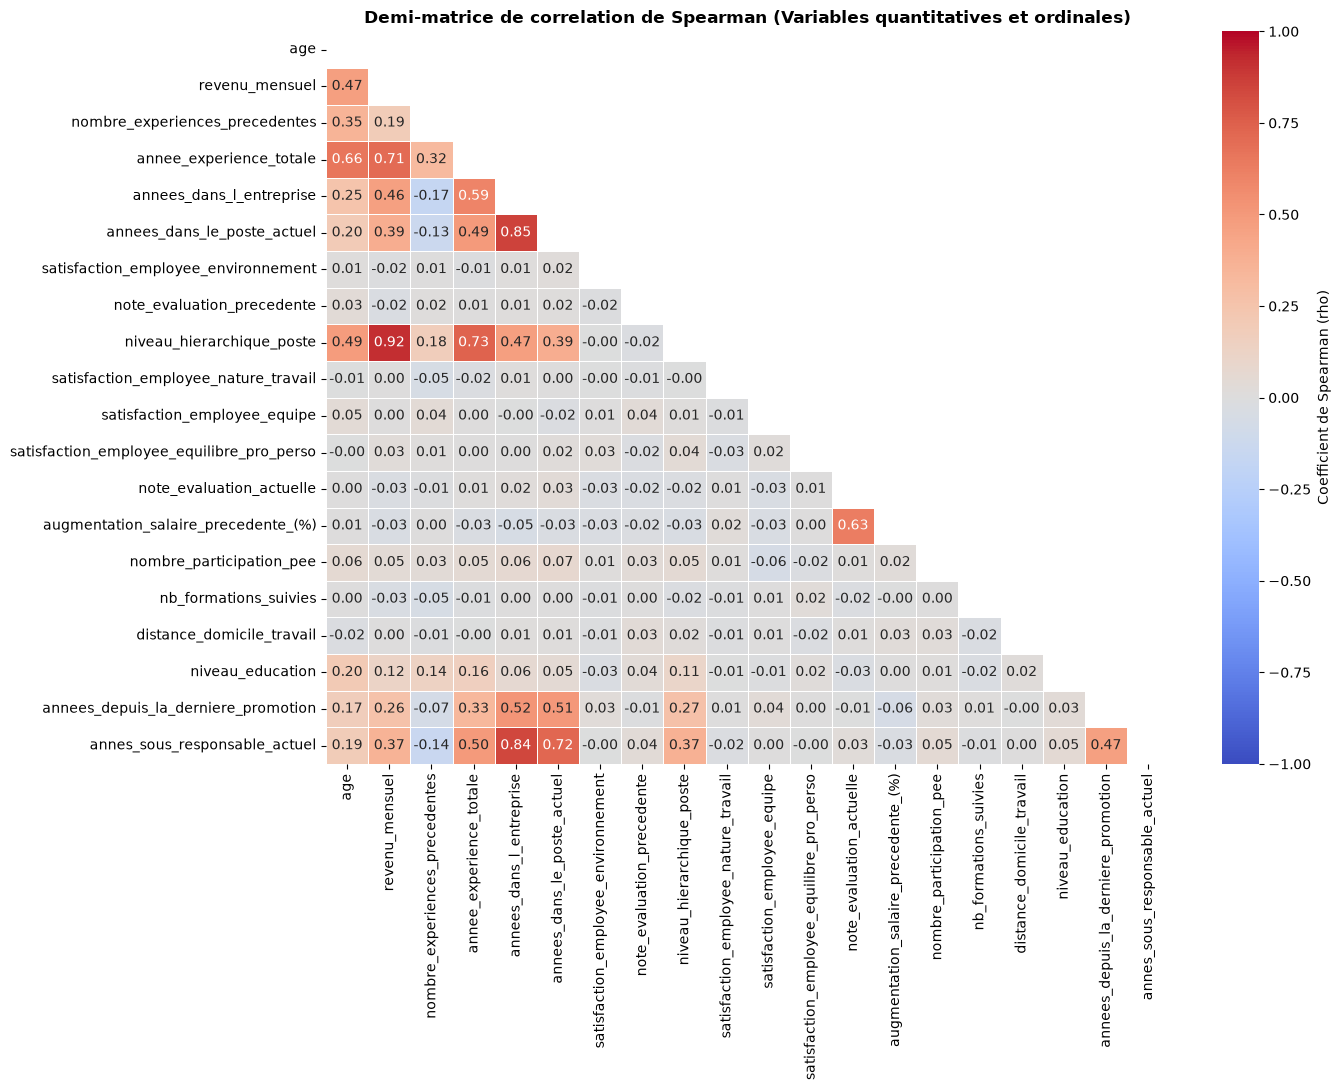

In [26]:
# Matrice de correlation de Spearman pour les variables quantitatives et ordinales, au vu de l'asymétrie et des valeurs outliers.
# On ne confronte pas les variables à la cible , c'est juste pour détecter les colinéarités et comprendre les données

# Selection des 20 variables quantitatives et ordinales
cols_numeriques = [
    col
    for col in df_jointure_clean.select_dtypes(include=["number"]).columns
    if col != "id_employee"
]

# Calcul de la matrice de Spearman
matrice_spearman = df_jointure_clean[cols_numeriques].corr(method="spearman")

# Masque triangulaire superieur pour ne garder que la moitie inferieure
masque_triangle = np.triu(np.ones_like(matrice_spearman, dtype=bool))

plt.figure(figsize=(14, 11))
sns.heatmap(
    matrice_spearman,
    mask=masque_triangle,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Coefficient de Spearman (rho)"},
)
plt.title(
    "Demi-matrice de correlation de Spearman (Variables quantitatives et ordinales)",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

On observe des multicolinéarités entre certaines variables = feature engineering ou suppression? :
- Quasi-colinéarité parfaite entre `niveau_hierarchique_poste` et `revenu_mensuel`.
-> Piste simple : supprimer `niveau_hierarchique_poste` pour éviter la redondance et la multicolinéarité.
-> Piste Feature Engineering : Création d'un indicateur de cohérence salariale : `ratio_salaire_echelon = revenu_mensuel / niveau_hierarchique_poste` (détection des sous-rémunérations par rapport au rang).

- Redondance forte entre `annees_dans_l_entreprise`, `annees_dans_le_poste_actuel` et `annes_sous_responsable_actuel`
-> Conservation prioritaire de `annees_dans_le_poste_actuel`** (signal prédictif de turnover le plus marqué à 0–2 ans)
-> Piste Feature Engineering : Remplacement par des métriques d'évolution métier :

temps_stagnation = annees_dans_l_entreprise - annees_dans_le_poste_actuel`

stabilite_manageriale = annes_sous_responsable_actuel / (annees_dans_l_entreprise + 1)

In [ ]:
# On fait aussi une corrélation de Pearson pour comparer les deux méthodes pour analyser les relations linéaires et comparer les résultats. 
# Cela permet de détecter les relations non-linéaires et l'asymétrie dans les données.

# Sélection des variables numériques (hors id)
cols_num_person = [
    col
    for col in df_jointure_clean.select_dtypes(include=["number"]).columns
    if col != "id_employee"
]

# Calcul des deux matrices en valeur absolue
corr_pearson = df_jointure_clean[cols_num_person].corr(method="pearson").abs()
corr_spearman = df_jointure_clean[cols_num_person].corr(method="spearman").abs()

# Extraction des paires uniques (triangle supérieur sans la diagonale)
masque = np.triu(np.ones(corr_pearson.shape), k=1).astype(bool)
comp_corr = pd.DataFrame({
    "Pearson": corr_pearson.where(masque).stack(),
    "Spearman": corr_spearman.where(masque).stack()
})
comp_corr["Ecart_Absolu"] = (comp_corr["Spearman"] - comp_corr["Pearson"]).abs()

print("--- TOP 8 DES PLUS FORTES COLINEARITES (PEARSON vs SPEARMAN) ---")
display(comp_corr.sort_values(by="Spearman", ascending=False).head(8).round(3))

print("--- TOP 8 DES PLUS GRANDS ECARTS (RELATIONS NON-LINEAIRES / ASYMETRIE) ---")
display(comp_corr.sort_values(by="Ecart_Absolu", ascending=False).head(8).round(3))

--- TOP 8 DES PLUS FORTES COLINEARITES (PEARSON vs SPEARMAN) ---


Pearson  \
revenu_mensuel              niveau_hierarchique_poste              0.950   
annees_dans_l_entreprise    annees_dans_le_poste_actuel            0.759   
                            annes_sous_responsable_actuel          0.769   
annee_experience_totale     niveau_hierarchique_poste              0.782   
annees_dans_le_poste_actuel annes_sous_responsable_actuel          0.714   
revenu_mensuel              annee_experience_totale                0.773   
age                         annee_experience_totale                0.680   
note_evaluation_actuelle    augmentation_salaire_precedente_(%)    0.774   

                                                                 Spearman  \
revenu_mensuel              niveau_hierarchique_poste               0.920   
annees_dans_l_entreprise    annees_dans_le_poste_actuel             0.854   
                            annes_sous_responsable_actuel           0.843   
annee_experience_totale     niveau_hierarchique_poste               0.735   
annees_dans_le_poste_actuel annes_sous_responsable_actuel           0.725   
revenu_mensuel              annee_experience_totale                 0.710   
age                         annee_experience_totale                 0.657   
note_evaluation_actuelle    augmentation_salaire_precedente_(%)     0.629   

                                                                 Ecart_Absolu  
revenu_mensuel              niveau_hierarchique_poste                   0.030  
annees_dans_l_entreprise    annees_dans_le_poste_actuel                 0.095  
                            annes_sous_responsable_actuel               0.074  
annee_experience_totale     niveau_hierarchique_poste                   0.048  
annees_dans_le_poste_actuel annes_sous_responsable_actuel               0.010  
revenu_mensuel              annee_experience_totale                     0.063  
age                         annee_experience_totale                     0.023  
note_evaluation_actuelle    augmentation_salaire_precedente_(%)         0.145

--- TOP 8 DES PLUS GRANDS ECARTS (RELATIONS NON-LINÉAIRES / ASYMETRIE) ---


Pearson  \
note_evaluation_actuelle       augmentation_salaire_precedente_(%)    0.774   
annees_dans_l_entreprise       annees_depuis_la_derniere_promotion    0.618   
                               annees_dans_le_poste_actuel            0.759   
niveau_hierarchique_poste      annees_depuis_la_derniere_promotion    0.354   
revenu_mensuel                 annees_depuis_la_derniere_promotion    0.345   
nombre_experiences_precedentes annee_experience_totale                0.238   
annees_dans_l_entreprise       annes_sous_responsable_actuel          0.769   
annee_experience_totale        annees_depuis_la_derniere_promotion    0.405   

                                                                    Spearman  \
note_evaluation_actuelle       augmentation_salaire_precedente_(%)     0.629   
annees_dans_l_entreprise       annees_depuis_la_derniere_promotion     0.520   
                               annees_dans_le_poste_actuel             0.854   
niveau_hierarchique_poste      annees_depuis_la_derniere_promotion     0.269   
revenu_mensuel                 annees_depuis_la_derniere_promotion     0.265   
nombre_experiences_precedentes annee_experience_totale                 0.315   
annees_dans_l_entreprise       annes_sous_responsable_actuel           0.843   
annee_experience_totale        annees_depuis_la_derniere_promotion     0.335   

                                                                    Ecart_Absolu  
note_evaluation_actuelle       augmentation_salaire_precedente_(%)         0.145  
annees_dans_l_entreprise       annees_depuis_la_derniere_promotion         0.098  
                               annees_dans_le_poste_actuel                 0.095  
niveau_hierarchique_poste      annees_depuis_la_derniere_promotion         0.085  
revenu_mensuel                 annees_depuis_la_derniere_promotion         0.080  
nombre_experiences_precedentes annee_experience_totale                     0.078  
annees_dans_l_entreprise       annes_sous_responsable_actuel               0.074  
annee_experience_totale        annees_depuis_la_derniere_promotion         0.070

Confirmation des variables multicolinéaires observées dans Sperman.
Confirmation de la supériorité de Spearman face aux outliers et paliers : annees_depuis_la_derniere_promotion, note_evaluation_actuelle...

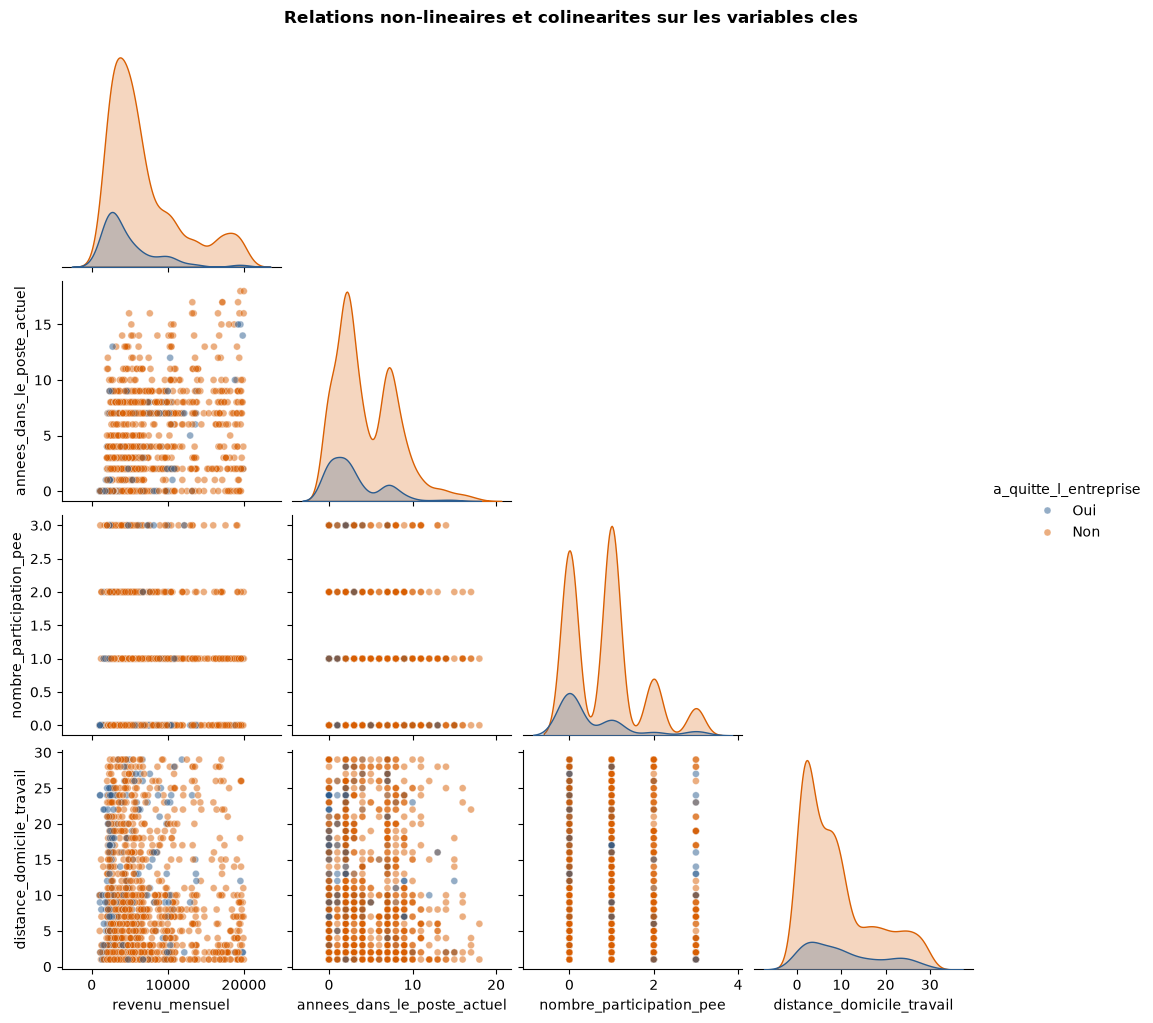

In [27]:
# Pairplot ciblé sur les fortes colinéarités (Quanti vs Quanti avec Cible)
# Selection des features d'anciennete et de remuneration les plus liees
cols_pairplot = [
    "revenu_mensuel",
    "annees_dans_le_poste_actuel",
    "nombre_participation_pee",
    "distance_domicile_travail",
]

# Nuages de points croises avec distribution diagonale
pairplot_fig = sns.pairplot(
    data=df_jointure_clean,
    vars=cols_pairplot,
    hue="a_quitte_l_entreprise",
    palette=["#2b5c8f", "#d95f02"],
    diag_kind="kde",
    corner=True,  # N'affiche que le triangle inferieur pour eviter les doublons
    plot_kws={"alpha": 0.5, "s": 25},
)

pairplot_fig.figure.suptitle(
    "Relations non-lineaires et colinearites sur les variables cles",
    y=1.02,
    fontweight="bold",
)
plt.show()

On oberve une prédominance dans les bas salaires des employés ayant démissionné aux alentours de 2500€ et en baisse jusqu'à 10000€ par mois

On observe une fréquence de démission plus élevée avant de 2 ans et aux alentours de 8 ans d'ancienneté

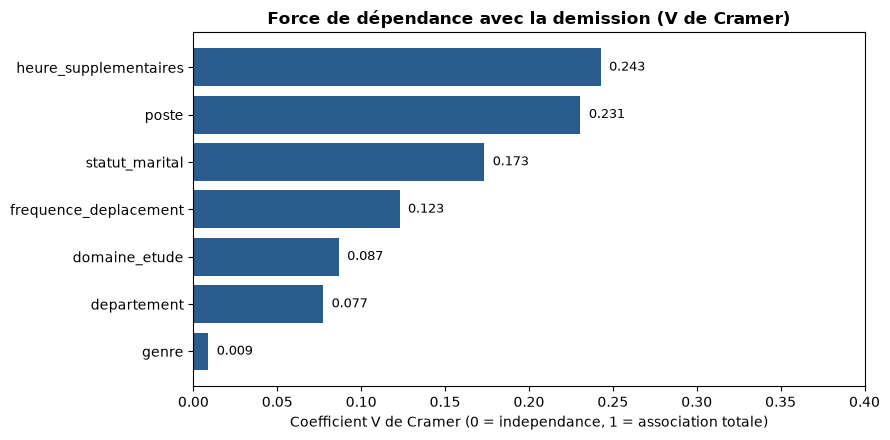

In [28]:
# V de Cramér issu du test du chi2 pour les variables catégorielles non numériques (nominales) et la variable cible démission binaire (Oui/Non)
# Cramer plutôt qu'un chi2 pour avoir un score de force de dépendance entre 0 et 1, plus facile à interpréter.


def calculer_cramers_v(serie_x, serie_y):
    tableau = pd.crosstab(serie_x, serie_y)
    chi2 = chi2_contingency(tableau)[0]
    taille = tableau.sum().sum()
    phi2 = chi2 / taille
    lignes, colonnes = tableau.shape
    # Formule corrigee pour petits et moyens echantillons
    phi2_corr = max(0, phi2 - ((colonnes - 1) * (lignes - 1)) / (taille - 1))
    lignes_corr = lignes - ((lignes - 1) ** 2) / (taille - 1)
    colonnes_corr = colonnes - ((colonnes - 1) ** 2) / (taille - 1)
    denominateur = min((colonnes_corr - 1), (lignes_corr - 1))
    return (
        np.sqrt(phi2_corr / denominateur)
        if denominateur > 0
        else 0.0
    )


cols_nominales = [
    "genre",
    "statut_marital",
    "departement",
    "poste",
    "heure_supplementaires",
    "domaine_etude",
    "frequence_deplacement",
]

scores_cramer = []
for variable in cols_nominales:
    score = calculer_cramers_v(
        df_jointure_clean[variable], df_jointure_clean["a_quitte_l_entreprise"]
    )
    scores_cramer.append({"Variable": variable, "V_Cramer": score})

df_cramer = pd.DataFrame(scores_cramer).sort_values(
    by="V_Cramer", ascending=True
)

plt.figure(figsize=(9, 4.5))
plt.barh(
    df_cramer["Variable"],
    df_cramer["V_Cramer"],
    color="#2b5c8f",
)
plt.title(
    "Force de dépendance avec la demission (V de Cramer)",
    fontweight="bold",
)
plt.xlabel("Coefficient V de Cramer (0 = independance, 1 = association totale)")
plt.xlim(0, 0.4)

# Affichage des valeurs numeriques au bout des barres
for index, valeur in enumerate(df_cramer["V_Cramer"]):
    plt.text(valeur + 0.005, index, f"{valeur:.3f}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

In [46]:
# On regarde les valeurs de poste et de statut marital pour identifier les postes à risque et les profils volatiles
# Calcul du taux de démission et des effectifs par poste exact
stats_postes = (
    df_jointure_clean.groupby("poste")["a_quitte_l_entreprise"]
    .agg(
        effectif="count",
        nb_departs=lambda s: (s == "Oui").sum(),
        taux_demission=lambda s: (s == "Oui").mean() * 100,
    )
    .sort_values(by="taux_demission", ascending=False)
)

print("CLASSEMENT DES POSTES PAR TAUX DE DEMISSION")
display(stats_postes.round(2))

stats_marital = (
    df_jointure_clean.groupby("statut_marital")["a_quitte_l_entreprise"]
    .agg(
        effectif="count",
        nb_departs=lambda s: (s == "Oui").sum(),
        taux_demission=lambda s: (s == "Oui").mean() * 100,
    )
    .sort_values(by="taux_demission", ascending=False)
)

print("CLASSEMENT DES STATUTS MARITAUX PAR TAUX DE DEMISSION")
display(stats_marital.round(2))

CLASSEMENT DES POSTES PAR TAUX DE DEMISSION


,effectif,nb_departs,taux_demission
poste,,,
Représentant Commercial,83,33,39.76
Consultant,259,62,23.94
Ressources Humaines,52,12,23.08
Cadre Commercial,326,57,17.48
Assistant de Direction,292,47,16.10
Tech Lead,145,10,6.90
Manager,131,9,6.87
Senior Manager,102,5,4.90
Directeur Technique,80,2,2.50


CLASSEMENT DES STATUTS MARITAUX PAR TAUX DE DEMISSION


,effectif,nb_departs,taux_demission
statut_marital,,,
Célibataire,470,120,25.53
Marié(e),673,84,12.48
Divorcé(e),327,33,10.09


Analyse V de Cramér

L'évaluation de la dépendance statistique entre les variables qualitatives nominales et l'attrition (`a_quitte_l_entreprise`) met en évidence quatre leviers explicatifs majeurs :

* `heure_supplementaires` : Plus forte intensité d'association du groupe nominal. Marqueur direct de charge de travail
* `poste` : Dépendance marquée liée à l'hétérogénéité des métiers 
* `statut_marital` : Signal démographique discriminant
* `frequence_deplacement` : Association modérée mais significative, confirmant l'impact du temps de trajet (fatigue?)


Préconisations de Feature Engineering :
- score_usure = heure_sup_bool * (5 - satisfaction_equilibre)` | Combine la surcharge objective constatée avec la dégradation perçue de l'équilibre personnel.
- ratio_heures_sup_salaire = heure_sup_bool / np.log1p(revenu_mensuel)` | Détecte les collaborateurs effectuant des heures supplémentaires pour un niveau de rémunération proportionnellement faible. |
- poste_a_risque = 1` si poste = Représentant Commercial, Consultant, Ressources Humaines, Cadre Commercial, Assistant de Direction sinon `0` | Isole les familles de postes subissant une attrition structurellement supérieure à la moyenne
- pression_trajet = deplacement_frequent_bool * distance_domicile_travail` | Amplifie la contrainte de distance domicile-travail pour les salariés contraints à des déplacements professionnels répétés. |
- profil_volatile = 1` si célibataire ET `nombre_participation_pee == 0`, sinon `0` | Capture le profil à haute propension au départ : mobilité personnelle maximale sans ancrage financier/capitalistique dans l'entreprise. |
- turnover_management = annees_dans_l_entreprise - annes_sous_responsable_actuel` | Mesure les ruptures managériales subies (changement fréquent de responsable ou départs successifs de la hiérarchie directe). |

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Feature Engineering</h3>
</div>

L'idée est de créer des features métier à partir des variables existantes, sans perdre les informations des variables initiales mais en éliminiant les variables en situation de colinéarité detectées dans les analyses multivariées. Procèdons par bloc suivant chaque analyse multivariée précédente. 

In [ ]:
# Bloc 1 : Spearman
# Indicateur de cohérence salariale : `ratio_salaire_echelon = revenu_mensuel / niveau_hierarchique_poste` (détection des sous-rémunérations par rapport au rang)
# Métriques d'évolution métier :
# temps_stagnation = annees_dans_l_entreprise - annees_dans_le_poste_actuel`
# stabilite_manageriale = annes_sous_responsable_actuel / (annees_dans_l_entreprise + 1)

# Initialisation du DataFrame pour le Feature Engineering
df_feature = df_jointure_clean.copy()

# Cohérence salariale par échelon hiérarchique
df_feature["ratio_salaire_echelon"] = (df_feature["revenu_mensuel"] / df_feature["niveau_hierarchique_poste"])

# Ancienneté cumulée hors du poste actuel
df_feature["temps_stagnation"] = (df_feature["annees_dans_l_entreprise"] - df_feature["annees_dans_le_poste_actuel"])

# Proportion de la carrière interne passée sous le manager actuel (+1 contre la division par 0)
df_feature["stabilite_manageriale"] = df_feature["annes_sous_responsable_actuel"] / (df_feature["annees_dans_l_entreprise"] + 1)

# Contrôle immédiat des 3 nouvelles variables
cols_b1 = ["ratio_salaire_echelon", "temps_stagnation", "stabilite_manageriale"]
display(df_feature[cols_b1].describe().round(2))


,ratio_salaire_echelon,temps_stagnation,stabilite_manageriale
count,1470.00,1470.00,1470.00
mean,2973.80,2.78,0.47
std,770.64,4.12,0.28
min,1009.00,0.00,0.00
25%,2394.12,1.00,0.29
50%,2856.50,1.00,0.50
75%,3478.83,3.00,0.67
max,4999.00,30.00,0.89


In [47]:
# Bloc 2 : Cramér

# score_usure = heure_sup_bool * (5 - satisfaction_equilibre)` | Combine la surcharge objective constatée avec la dégradation perçue de l'équilibre personnel
# ratio_heures_sup_salaire = heure_sup_bool / np.log1p(revenu_mensuel)` | Détecte les collaborateurs effectuant des heures supplémentaires pour un niveau de rémunération proportionnellement faible
# poste_a_risque = 1` si poste = Représentant Commercial, Consultant, Ressources Humaines, Cadre Commercial, Assistant de Direction sinon `0` | Isole les familles de postes subissant une attrition structurellement supérieure à la moyenne
# pression_trajet = deplacement_frequent_bool * distance_domicile_travail` | Amplifie la contrainte de distance domicile-travail pour les salariés contraints à des déplacements professionnels répétés
# profil_volatile = 1` si célibataire ET `nombre_participation_pee == 0`, sinon `0` | Capture le profil à haute propension au départ : mobilité personnelle maximale sans ancrage financier/capitalistique dans l'entreprise
# turnover_management = annees_dans_l_entreprise - annes_sous_responsable_actuel` | Mesure les ruptures managériales subies (changement fréquent de responsable ou départs successifs de la hiérarchie directe)


# Conversion temporaire des conditions qualitatives en masques binaires (0/1)
heure_sup_bool = (df_feature["heure_supplementaires"] == "Oui").astype(int)
deplacement_frequent_bool = (df_feature["frequence_deplacement"].isin(["Frequent", "Fréquent"]).astype(int))
celibataire_bool = (df_feature["statut_marital"].isin(["Célibataire", "Celibataire"]).astype(int))

# Surcharge & Usure
df_feature["usure_heures_sup"] = heure_sup_bool * (5 - df_feature["satisfaction_employee_equilibre_pro_perso"])

# Pression salariale de charge
df_feature["ratio_heures_sup_salaire"] = heure_sup_bool / np.log1p(df_feature["revenu_mensuel"])

# Pôle métier à risque (vérification de la casse exacte des intitulés de poste)
postes_risque = [
    "Représentant Commercial",
    "Consultant",
    "Ressources Humaines",
    "Cadre Commercial",
    "Assistant de Direction",
]
df_feature["poste_a_risque"] = (df_feature["poste"].isin(postes_risque).astype(int))

# Fatigue trajet domicile-travail
df_feature["pression_trajet"] = (deplacement_frequent_bool * df_feature["distance_domicile_travail"])

# Indice de situation maritale
df_feature["profil_volatile"] = ((celibataire_bool == 1) & (df_feature["nombre_participation_pee"] == 0)).astype(int)

# Instabilité de l'encadrement
df_feature["turnover_management"] = (df_feature["annees_dans_l_entreprise"] - df_feature["annes_sous_responsable_actuel"])

# Contrôle rapide des valeurs générées
cols_b2 = [
    "usure_heures_sup",
    "ratio_heures_sup_salaire",
    "poste_a_risque",
    "pression_trajet",
    "profil_volatile",
    "turnover_management",
]
print("Répartition des nouvelles variables du Bloc 2 :")
display(df_feature[cols_b2].describe().round(2))

Répartition des nouvelles variables du Bloc 2 :


,usure_heures_sup,ratio_heures_sup_salaire,poste_a_risque,pression_trajet,profil_volatile,turnover_management
count,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00
mean,0.64,0.03,0.69,1.75,0.32,2.89
std,1.09,0.05,0.46,5.15,0.47,4.08
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00,1.00
50%,0.00,0.00,1.00,0.00,0.00,1.00
75%,2.00,0.11,1.00,0.00,1.00,3.00
max,4.00,0.14,1.00,29.00,1.00,34.00


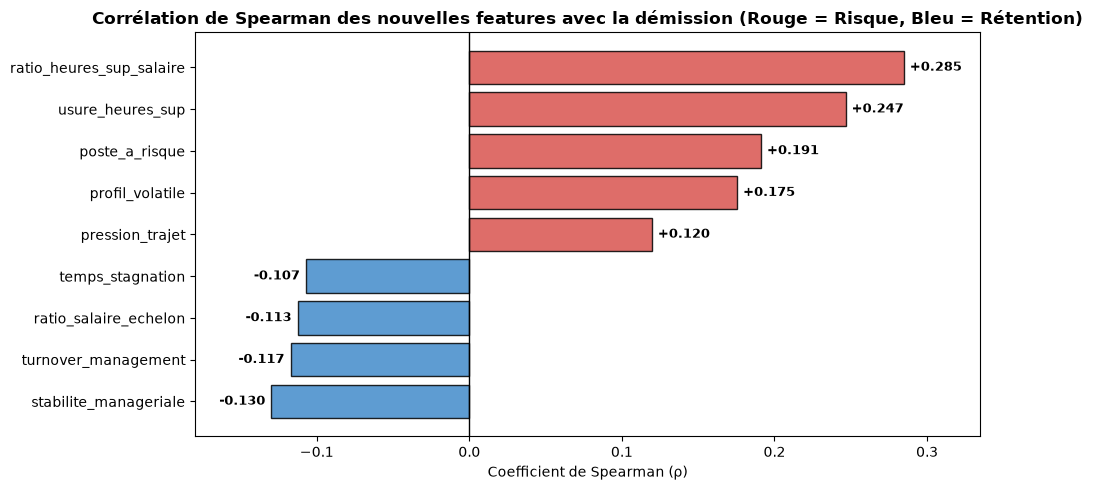

In [48]:
# Un spearman sur les nouvelles features
# Liste complète des 9 nouvelles features (Bloc 1 + Bloc 2)
nouvelles_features = [
    "ratio_salaire_echelon",
    "temps_stagnation",
    "stabilite_manageriale",
    "usure_heures_sup",
    "ratio_heures_sup_salaire",
    "poste_a_risque",
    "pression_trajet",
    "profil_volatile",
    "turnover_management",
]

# Encodage temporaire de la cible en binaire (0/1) pour le calcul de corrélation
cible_num = df_feature["a_quitte_l_entreprise"].map({"Oui": 1, "Non": 0})

# Calcul de la corrélation de Spearman entre les nouvelles features et la variable cible
corrs_fe = (
    df_feature[nouvelles_features]
    .apply(lambda col: col.corr(cible_num, method="spearman"))
    .sort_values()
)

plt.figure(figsize=(10, 5))
couleurs = ["#d9534f" if val > 0 else "#428bca" for val in corrs_fe.values]
bars = plt.barh(corrs_fe.index, corrs_fe.values, color=couleurs, edgecolor="black", alpha=0.85)

plt.axvline(0, color="black", linewidth=1)
plt.title(
    "Corrélation de Spearman des nouvelles features avec la démission (Rouge = Risque, Bleu = Rétention)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Coefficient de Spearman (ρ)")
plt.xlim(corrs_fe.min() - 0.05, corrs_fe.max() + 0.05)

# Affichage des valeurs exactes au bout des barres
for bar in bars:
    largeur = bar.get_width()
    align = "left" if largeur >= 0 else "right"
    decalage = 0.004 if largeur >= 0 else -0.004
    plt.text(
        largeur + decalage,
        bar.get_y() + bar.get_height() / 2,
        f"{largeur:+.3f}",
        va="center",
        ha=align,
        fontsize=9,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

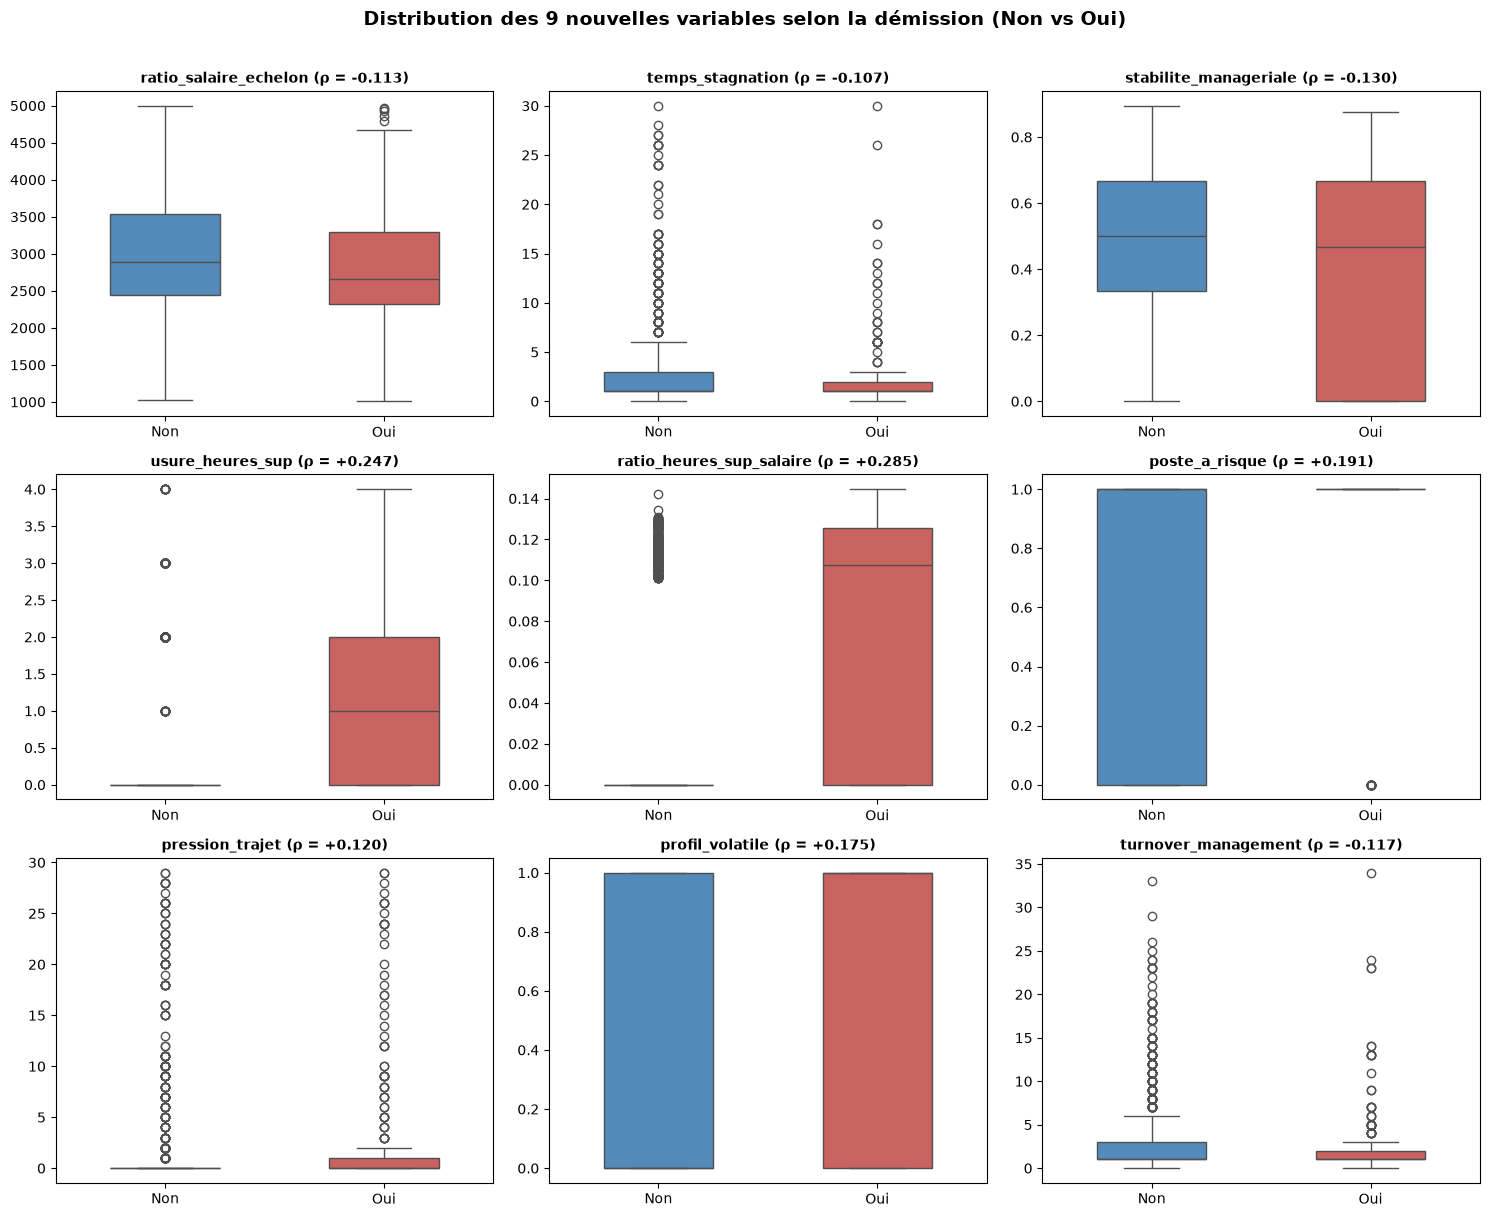

In [49]:
# Boxplot des nouvelles features

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for idx, col in enumerate(nouvelles_features):
    sns.boxplot(
        data=df_feature,
        x="a_quitte_l_entreprise",
        y=col,
        hue="a_quitte_l_entreprise",
        order=["Non", "Oui"],
        palette={"Non": "#428bca", "Oui": "#d9534f"},
        legend=False,
        ax=axes[idx],
        width=0.5,
    )
    axes[idx].set_title(f"{col} (ρ = {corrs_fe[col]:+.3f})", fontsize=10, fontweight="bold")
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel("")

plt.suptitle(
    "Distribution des 9 nouvelles variables selon la démission (Non vs Oui)",
    fontsize=14,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

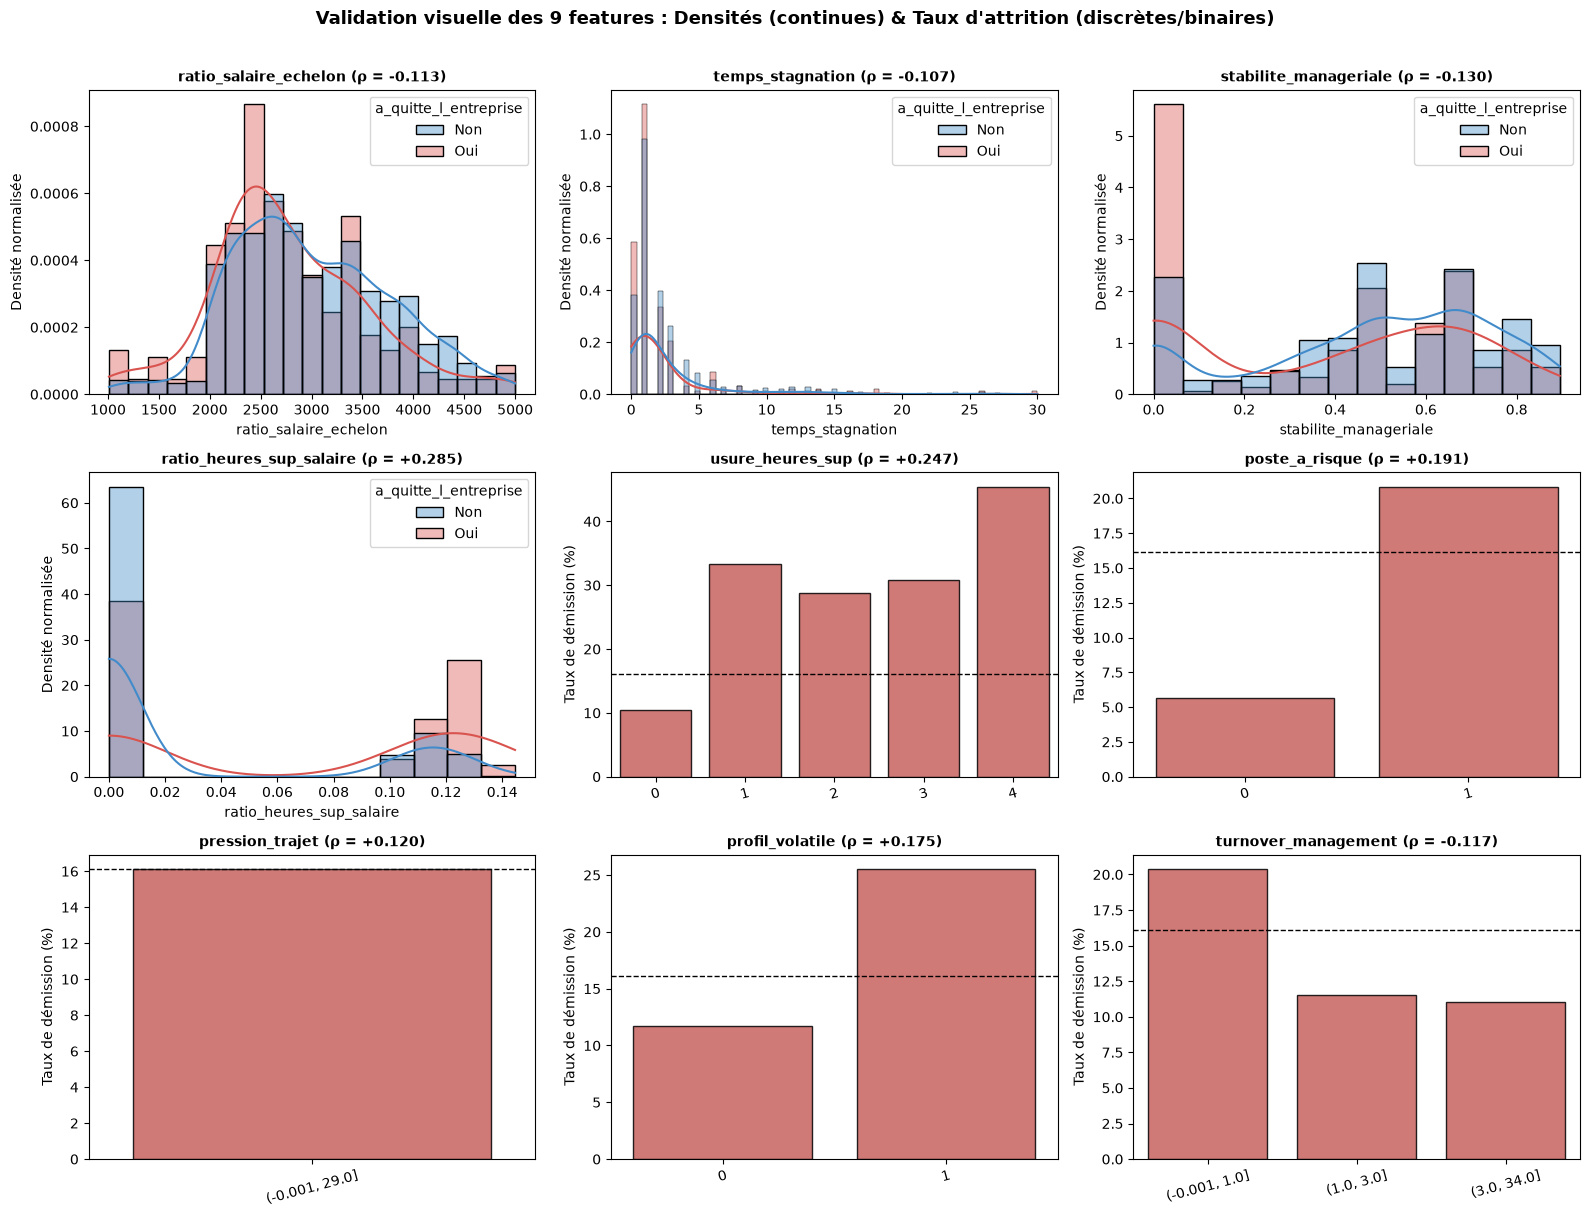

In [52]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Séparation des 9 features selon leur nature visuelle optimale
vars_continues = [
    "ratio_salaire_echelon",
    "temps_stagnation",
    "stabilite_manageriale",
    "ratio_heures_sup_salaire",
]

vars_discretes_binaires = [
    "usure_heures_sup",
    "poste_a_risque",
    "pression_trajet",
    "profil_volatile",
    "turnover_management",
]

cible_num = df_feature["a_quitte_l_entreprise"].map({"Oui": 1, "Non": 0})
taux_moyen = cible_num.mean() * 100

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

# 1. Histogrammes KDE normalisés pour les 4 variables continues
for idx, col in enumerate(vars_continues):
    sns.histplot(
        data=df_feature,
        x=col,
        hue="a_quitte_l_entreprise",
        hue_order=["Non", "Oui"],
        palette={"Non": "#428bca", "Oui": "#d9534f"},
        stat="density",
        common_norm=False,
        kde=True,
        alpha=0.4,
        ax=axes[idx],
    )
    rho = df_feature[col].corr(cible_num, method="spearman")
    axes[idx].set_title(f"{col} (ρ = {rho:+.3f})", fontsize=10, fontweight="bold")
    axes[idx].set_ylabel("Densité normalisée")

# 2. Barplots du taux de démission (%) pour les 5 variables binaires / discrètes
for offset, col in enumerate(vars_discretes_binaires):
    ax = axes[len(vars_continues) + offset]
    
    # Regroupement en 4 quantiles si la variable a trop de valeurs entières distinctes (ex: pression_trajet)
    if df_feature[col].nunique() > 6:
        serie_groupe = pd.qcut(df_feature[col], q=4, duplicates="drop").astype(str)
    else:
        serie_groupe = df_feature[col]

    taux_par_val = (
        df_feature.assign(groupe=serie_groupe, cible=cible_num * 100)
        .groupby("groupe", observed=False)["cible"]
        .mean()
    )

    sns.barplot(
        x=taux_par_val.index,
        y=taux_par_val.values,
        color="#d9534f",
        alpha=0.85,
        edgecolor="black",
        ax=ax,
    )
    ax.axhline(taux_moyen, color="black", linestyle="--", linewidth=1, label="Moyenne (16.1%)")
    rho = df_feature[col].corr(cible_num, method="spearman")
    ax.set_title(f"{col} (ρ = {rho:+.3f})", fontsize=10, fontweight="bold")
    ax.set_ylabel("Taux de démission (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle(
    "Validation visuelle des 9 features : Densités (continues) & Taux d'attrition (discrètes/binaires)",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Nettoyage des colonnes avant entrainement</h3>
</div>

In [ ]:
# On visualise le dataset et ses colonnes
df_non_residential_log.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity,SiteEnergyUse_log,TotalGHGEmissions_log
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83,15.793246,5.525373
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86,15.942305,5.693261
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19,18.100297,7.645053
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67,15.731637,5.660979
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88,16.466822,6.226556


In [ ]:
df_non_residential_log.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity,SiteEnergyUse_log,TotalGHGEmissions_log
count,1485.000000,1485.0,1473.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1.485000e+03,1485.000000,1.485000e+03,1.481000e+03,719.000000,241.000000,1027.000000,1485.000000,1484.000000,1485.000000,1485.000000,1.485000e+03,1.484000e+03,1.485000e+03,1.485000e+03,1.485000e+03,1.485000e+03,1.485000e+03,0.0,1485.000000,1485.000000,1485.000000,1485.000000
mean,15941.906397,2016.0,98116.771894,4.332660,47.614965,-122.333171,1961.876768,1.185859,4.195960,1.207530e+05,12973.248485,1.077797e+05,1.026345e+05,36088.249370,11452.353528,65.776047,71.024512,73.392318,174.378855,176.426936,8.321387e+06,7.861282e+06,5.524537e+05,1.723816e+06,5.881659e+06,1.756844e+04,1.756844e+06,NaN,176.952141,1.555421,14.903819,3.982115
std,13676.987151,0.0,18.001196,2.208728,0.048692,0.024550,32.190183,3.099507,6.818398,3.089471e+05,43104.199701,2.958018e+05,2.897981e+05,65095.740278,27904.903737,28.211408,72.658737,73.597040,180.658993,180.592332,2.962525e+07,1.953123e+07,5.818374e+06,6.279846e+06,2.142684e+07,6.129597e+04,6.129597e+06,NaN,661.889792,2.180353,1.324265,1.441929
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.411820,1900.000000,0.000000,0.000000,1.128500e+04,0.000000,1.128500e+04,7.583000e+03,0.000000,0.000000,1.000000,0.700000,0.000000,2.100000,0.000000,1.680890e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN,0.120000,0.000000,9.729723,0.113329
25%,574.000000,2016.0,98105.000000,2.000000,47.582900,-122.343280,1930.000000,1.000000,1.000000,2.952500e+04,0.000000,2.858400e+04,2.626300e+04,4708.500000,1686.000000,49.000000,33.700001,35.400002,76.400002,79.099998,1.245924e+06,1.301256e+06,0.000000e+00,2.112968e+05,7.209450e+05,0.000000e+00,0.000000e+00,NaN,19.930000,0.350000,14.035389,3.041184
50%,21103.000000,2016.0,98109.000000,4.000000,47.611700,-122.333160,1965.000000,1.000000,2.000000,4.924900e+04,0.000000,4.741500e+04,4.544200e+04,10853.000000,5000.000000,73.000000,51.000000,53.400002,130.699997,133.500000,2.581742e+06,2.717591e+06,0.000000e+00,4.758666e+05,1.623657e+06,4.768320e+03,4.768320e+05,NaN,49.530000,0.850000,14.763975,3.922567
75%,24532.000000,2016.0,98125.000000,7.000000,47.648820,-122.322320,1988.000000,1.000000,4.000000,1.068600e+05,0.000000,9.630000e+04,9.447000e+04,32756.500000,10000.000000,89.000000,79.500000,82.925001,200.500000,202.699997,6.917280e+06,7.167893e+06,0.000000e+00,1.466880e+06,5.004995e+06,1.437252e+04,1.437252e+06,NaN,134.820000,1.810000,15.749533,4.911330
max,50224.000000,2016.0,98199.000000,7.000000,47.733870,-122.258640,2015.000000,111.000000,99.000000,9.320156e+06,512608.000000,9.320156e+06,9.320156e+06,441551.000000,303910.000000,100.000000,834.400024,834.400024,2620.000000,2620.000000,8.739237e+08,2.966717e+08,1.349435e+08,1.925775e+08,6.570744e+08,1.381912e+06,1.381912e+08,NaN,12307.160000,25.710000,20.588504,9.418018


In [ ]:
# Vérification de présence d'incohérences
# Incohérence : sous-surfaces supérieures à la surface totale
incoherence_surface = (
    df_non_residential_log['PropertyGFABuilding(s)'] + df_non_residential_log['PropertyGFAParking']
) > (df_non_residential_log['PropertyGFATotal'] * 1.01)  # tolérance de 1% pour arrondis

print("Bâtiments avec sous-surfaces > surface totale :", incoherence_surface.sum())

# Surfaces <= 0
zero_gfa = df_non_residential_log['PropertyGFATotal'] <= 0
print("Bâtiments avec surface totale <= 0 :", zero_gfa.sum())

# Consommation d'énergie <= 0
zero_energy = df_non_residential_log['SiteEnergyUse(kBtu)'] <= 0
print("Bâtiments avec consommation <= 0 :", zero_energy.sum())

# Émissions de GES < 0 (certains bâtiments à énergie positive ou compensation affichent parfois des valeurs négatives)
neg_ghg = df_non_residential_log['TotalGHGEmissions'] < 0
print("Bâtiments avec émissions GES < 0 :", neg_ghg.sum())

# Années aberrantes (Seattle a été fondée au 18ème )
annee_incoherente = (
    (df_non_residential_log['YearBuilt'] > 2016) | 
    (df_non_residential_log['YearBuilt'] < 1800)
)
print("Bâtiments avec année de construction incohérente :", annee_incoherente.sum())

# Ratio surface par étage
surface_par_etage = df_non_residential_log['PropertyGFATotal'] / df_non_residential_log['NumberofFloors']

# Moins de 100 sq.ft (~9 m²) par étage pour un bâtiment non résidentiel
etage_microscopique = surface_par_etage < 100
print("Bâtiments avec surface par étage anormalement basse (< 100 sq.ft) :", etage_microscopique.sum())

# Somme des incohérences 
total_anomalies = (
    incoherence_surface.sum()
    + zero_gfa.sum()
    + zero_energy.sum()
    + neg_ghg.sum()
    + annee_incoherente.sum()
    + etage_microscopique.sum()
)

if total_anomalies == 0:
    print("\nVérification terminée : 0 incohérence détectée. Le jeu de données est cohérent")
else:
    print(f"Attention : {total_anomalies} bâtiments avec des données incohérentes détectés.")

Bâtiments avec sous-surfaces > surface totale : 0
Bâtiments avec surface totale <= 0 : 0
Bâtiments avec consommation <= 0 : 0
Bâtiments avec émissions GES < 0 : 0
Bâtiments avec année de construction incohérente : 0
Bâtiments avec surface par étage anormalement basse (< 100 sq.ft) : 0

Vérification terminée : 0 incohérence détectée. Le jeu de données est cohérent


In [ ]:
# Taux de valeurs manquantes par colonne, trié par ordre décroissant
missing_summary = pd.DataFrame({
    'NaN_count': df_non_residential_log.isna().sum(),
    'NaN_pct': (df_non_residential_log.isna().mean() * 100).round(2)
})

# Affichage des colonnes qui ont au moins 1 valeur manquante
missing_summary[missing_summary['NaN_count'] > 0].sort_values(by='NaN_count', ascending=False)

,NaN_count,NaN_pct
Comments,1485,100.00
Outlier,1469,98.92
YearsENERGYSTARCertified,1390,93.60
ThirdLargestPropertyUseType,1244,83.77
ThirdLargestPropertyUseTypeGFA,1244,83.77
SecondLargestPropertyUseTypeGFA,766,51.58
SecondLargestPropertyUseType,766,51.58
ENERGYSTARScore,458,30.84
ZipCode,12,0.81
LargestPropertyUseType,4,0.27


In [ ]:
print(f"Dimensions du dataset df_non_residential_log : {df_non_residential_log.shape}")

Dimensions du dataset df_non_residential_log : (1485, 48)


In [ ]:
# On remarque des étages à 0, verification des lignes
df_zero_floors = df_non_residential_log[df_non_residential_log['NumberofFloors'] == 0]

print(f"Nombre de bâtiments concernés : {len(df_zero_floors)}")
df_zero_floors

Nombre de bâtiments concernés : 11


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity,SiteEnergyUse_log,TotalGHGEmissions_log
166,267,2016,NonResidential,Hotel,Grand Hyatt Seattle,721 Pine St,Seattle,WA,98101.0,6792120000,7,DOWNTOWN,47.61275,-122.33330,1999,1.0,0,934292,0,934292,"Hotel, Other, Parking, Restaurant, Retail Store",Hotel,495536.0,Parking,438756.0,Restaurant,49700.0,NaN,NaN,117.900002,120.500000,272.899994,278.200012,6.504728e+07,66502836.0,0.0,1.153696e+07,39364114.0,256831.625000,25683162.0,False,NaN,Compliant,NaN,1638.46,1.75,17.990625,7.402122
487,656,2016,NonResidential,Medical Office,Arnold Pavilion,1221 Madison Street,Seattle,WA,98104.0,8725990000,3,EAST,47.60979,-122.32298,2004,1.0,0,225982,0,225982,Medical Office,Medical Office,200184.0,NaN,NaN,NaN,NaN,NaN,53.0,102.699997,103.699997,246.899994,245.300003,2.056062e+07,20764814.0,7815663.0,3.735333e+06,12744957.0,0.000000,0.0,False,NaN,Compliant,NaN,692.12,3.06,16.838888,6.541203
564,758,2016,NonResidential,Other,Pacific Place,600 Pine Street,Seattle,WA,98101.0,6600470000,7,DOWNTOWN,47.61289,-122.33531,1999,1.0,0,947987,0,947987,"Office, Other - Entertainment/Public Assembly,...",Other - Mall,561684.0,Other - Entertainment/Public Assembly,100000.0,Restaurant,80000.0,NaN,NaN,62.299999,62.099998,195.600006,194.899994,4.651096e+07,46343304.0,0.0,1.363158e+07,46510954.0,0.000000,0.0,False,NaN,Compliant,NaN,324.25,0.34,17.655199,5.784594
1754,23311,2016,NonResidential,Medical Office,HART First Hill LLC,1124 Columbia Street,Seattle,WA,98104.0,8590900646,3,EAST,47.60862,-122.32372,1945,1.0,0,274568,0,274568,"Medical Office, Parking",Medical Office,228133.0,Parking,135954.0,NaN,NaN,NaN,52.0,111.000000,111.199997,235.500000,233.100006,2.531153e+07,25358122.0,13296249.0,3.521476e+06,12015275.0,0.000000,0.0,False,NaN,Compliant,NaN,1110.07,4.04,17.046770,7.013079
1993,24086,2016,Campus,Other,(ID#24086)Campus1:KC Metro Transit Atlantic Ce...,1333 AIRPORT WAY S,Seattle,WA,98134.0,7666203387,2,GREATER DUWAMISH,47.59042,-122.32498,1991,10.0,0,230971,0,230971,"Other, Parking",Other,230970.0,Parking,0.0,NaN,NaN,NaN,NaN,91.000000,96.199997,235.100006,242.199997,2.102229e+07,22230844.0,0.0,4.519276e+06,15419770.0,56025.152340,5602515.0,False,NaN,Compliant,NaN,405.05,1.75,16.861094,6.006476
3130,40028,2016,NonResidential,Warehouse,Sandpoint #5,7561 63rd Ave NE,Seattle,WA,98115.0,0225049077,4,NORTHEAST,47.68454,-122.26235,1940,1.0,0,384772,0,384772,"Non-Refrigerated Warehouse, Office",Non-Refrigerated Warehouse,349953.0,Office,63872.0,NaN,NaN,NaN,69.0,36.700001,39.000000,84.099998,86.500000,1.520676e+07,16139557.0,0.0,2.642108e+06,9014872.0,61918.878910,6191888.0,False,NaN,Compliant,NaN,391.70,1.02,16.537251,5.973046
3131,40031,2016,NonResidential,Medical Office,Sandpoint #25,6222 NE 74th St,Seattle,WA,98115.0,0225049077,4,NORTHEAST,47.68240,-122.26223,1960,1.0,0,30287,0,30287,Medical Office,Medical Office,28050.0,NaN,NaN,NaN,NaN,NaN,32.0,78.199997,81.300003,217.399994,220.600006,2.193115e+06,2279632.5,0.0,5.320647e+05,1815405.0,3777.100342,377710.0,False,NaN,Compliant,NaN,32.72,1.08,14.600834,3.518091
3132,40034,2016,NonResidential,Small- and Mid-Sized Office,Sandpoint #29,6200 NE 74th ST,Seattle,WA,98115.0,0225049077,4,NORTHEAST,47.68254,-122.26299,1960,1.0,0,21931,0,219

In [ ]:
# Au vu du nombre et des batiements il s'agit d'une erreur on corrige les 0 en 1
df_non_residential_log['NumberofFloors'] = df_non_residential_log['NumberofFloors'].apply(lambda x: 1 if x == 0 else x)

In [ ]:
print("Modalités PrimaryPropertyType :", df_non_residential_log['PrimaryPropertyType'].nunique())
print("Modalités LargestPropertyUseType :", df_non_residential_log['LargestPropertyUseType'].nunique())

Modalités PrimaryPropertyType : 18
Modalités LargestPropertyUseType : 50


In [ ]:
# On identifie les energies utilisées qui influenceront les émissions et la consommation d'energie
# Utilisation de gaz (1 si > 0, sinon 0)
df_non_residential_log['HasGas'] = (df_non_residential_log['NaturalGas(kBtu)'] > 0).astype(int)

# Utilisation de la vapeur  (1 si > 0, sinon 0)
df_non_residential_log['HasSteam'] = (df_non_residential_log['SteamUse(kBtu)'] > 0).astype(int)

In [ ]:
# On va créer un dataset selectionné qui ne contiendra que les colonnes qui peuvent corréler la consommation
# On ne conservera donc pas les colonnes avec plus de 50% de Nan (qui ne semble pas utiles), les identifiants artificiels (id), les consommations partielles (que electricité par ex)
# Définition explicite des colonnes à conserver : 
colonnes_selectionees = [
    # Type et usage
    'PrimaryPropertyType', # LargestPropertyUseType aurait été intéressante et plus détaillée mais est déclarative -> donc pas dispo si pas d'enquete et peut être trop détaillée
    'Neighborhood',
    
    # Caractéristiques
    'YearBuilt',
    'NumberofBuildings',
    'NumberofFloors',
    'PropertyGFATotal',
    'PropertyGFABuilding(s)',
    'PropertyGFAParking',

    # Type d'energie utilisée
    'HasGas',
    'HasSteam',
       
    # Target en log (on garde les brutes pour les garder à dispo)
    'SiteEnergyUse(kBtu)',
    'SiteEnergyUse_log',
    'TotalGHGEmissions',
    'TotalGHGEmissions_log'
]

# Nouveau DataFrame dédié à l'analyse
df_colonnes_selectionees = df_non_residential_log[colonnes_selectionees].copy()

print(f"Dimensions du nouveau dataset : {df_colonnes_selectionees.shape}")
df_colonnes_selectionees.head(3)

Dimensions du nouveau dataset : (1485, 14)


,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFABuilding(s),PropertyGFAParking,HasGas,HasSteam,SiteEnergyUse(kBtu),SiteEnergyUse_log,TotalGHGEmissions,TotalGHGEmissions_log
0,Hotel,DOWNTOWN,1927,1.0,12,88434,88434,0,1,1,7226362.5,15.793246,249.98,5.525373
1,Hotel,DOWNTOWN,1996,1.0,11,103566,88502,15064,1,0,8387933.0,15.942305,295.86,5.693261
2,Hotel,DOWNTOWN,1969,1.0,41,956110,759392,196718,1,1,72587024.0,18.100297,2089.28,7.645053


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Vérification des corrélations</h3>
</div>

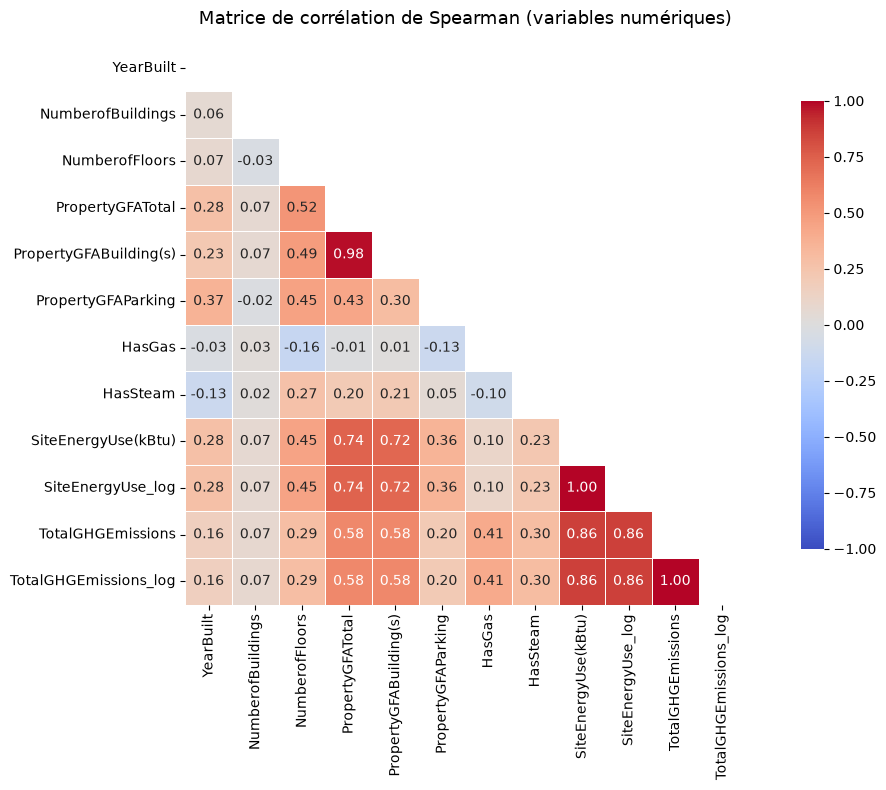

In [ ]:
# On conserve uniquement les colonnes numériques, on regardera les colonnes textuelles après
num_cols = df_colonnes_selectionees.select_dtypes(include=['int64', 'float64']).columns

# Calcul de la matrice de corrélation de Spearman (on met spearman plutôt que pearson a cause des outliers)
corr = df_colonnes_selectionees[num_cols].corr(method='spearman')

# Masque pour masquer le triangle supérieur
mask = np.triu(np.ones_like(corr, dtype=bool))

# Tracé du demi-heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Matrice de corrélation de Spearman (variables numériques)", fontsize=13, pad=15)
plt.tight_layout()

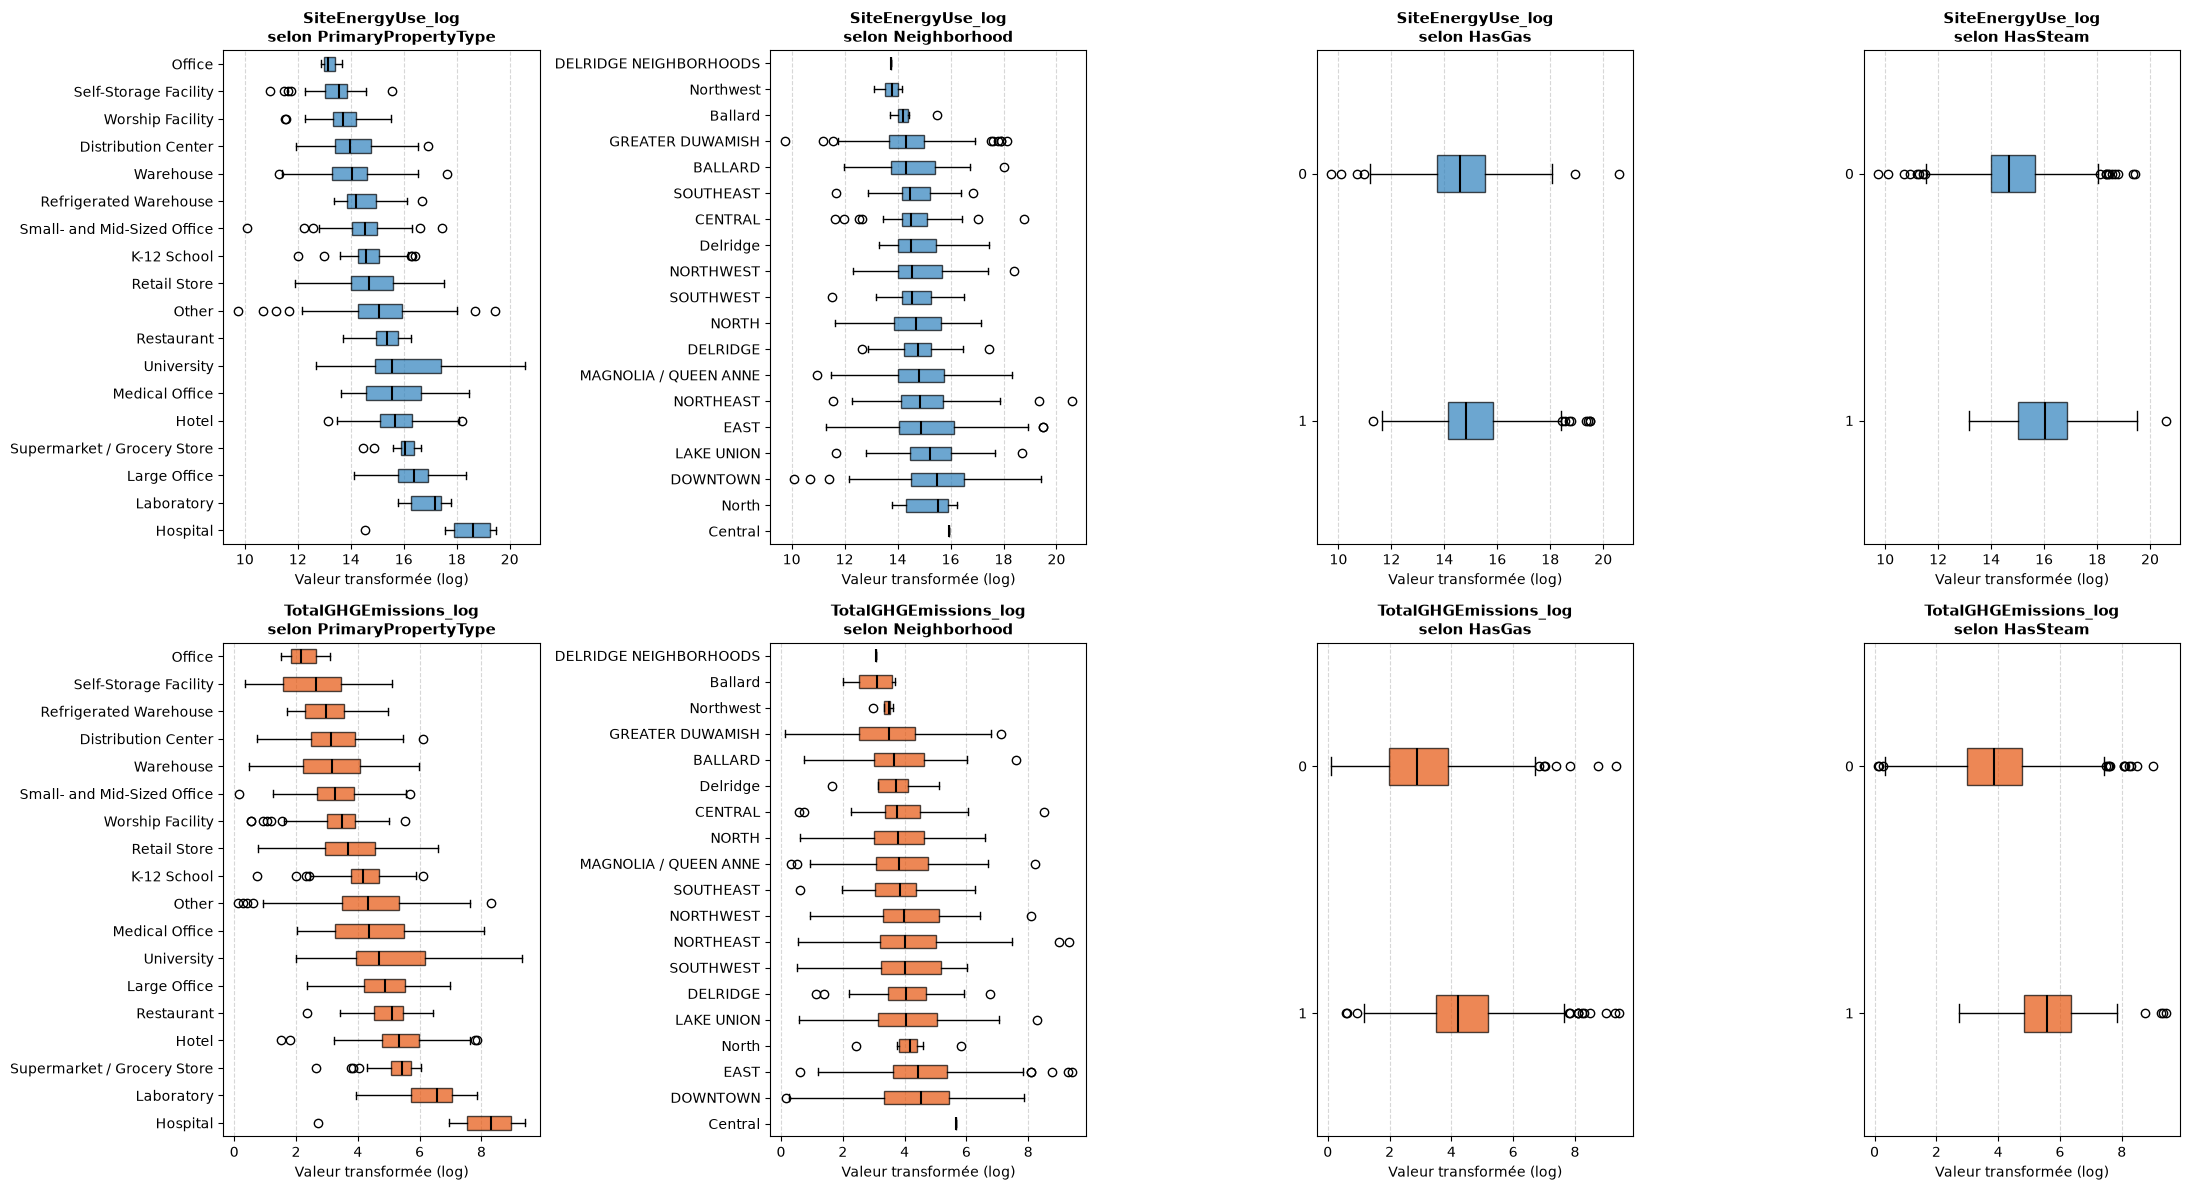

In [ ]:
# On regarde maintenant les variables qualitatives
fig, axes = plt.subplots(2, 4, figsize=(22, 12))

categorical_vars = ['PrimaryPropertyType', 'Neighborhood', 'HasGas', 'HasSteam']
targets = ['SiteEnergyUse_log', 'TotalGHGEmissions_log']

for row_idx, target in enumerate(targets):
    for col_idx, cat in enumerate(categorical_vars):
        ax = axes[row_idx, col_idx]
        
        # Tri des catégories par médiane décroissante
        order = (
            df_colonnes_selectionees.groupby(cat)[target]
            .median()
            .sort_values(ascending=False)
            .index.tolist()
        )
        
        # Préparation des séries de données ordonnées
        data_to_plot = [
            df_colonnes_selectionees.loc[df_colonnes_selectionees[cat] == val, target].dropna().values
            for val in order
        ]
        
        # Tracé natif avec Matplotlib (aucun conflit de version ou de positions)
        color_box = "#2e81bd" if row_idx == 0 else '#e6550d'
        
        # Boxplot avec la syntaxe moderne Matplotlib
        bp = ax.boxplot(
            data_to_plot,
            orientation='horizontal',
            patch_artist=True,
            tick_labels=[str(v) for v in order],
            boxprops=dict(facecolor=color_box, alpha=0.7, edgecolor='black'),
            medianprops=dict(color='black', linewidth=1.5)
        )
        
        ax.set_title(f"{target}\nselon {cat}", fontsize=11, fontweight='bold')
        ax.set_xlabel("Valeur transformée (log)")
        ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# On va créer un dataset qui ne contiendra que les colonnes qui semblent corrélées à la consommation d'energie ou les émissions
# On se base sur les colonnes avec corrélations observées quantitatives et qualitatives
# Définition explicite des colonnes à conserver : 
colonnes_conservees = [
    # Type et usage
    'PrimaryPropertyType',
    'Neighborhood', # semble moins impactante mais affinera la fiabilité des prédictions
    
    # Caractéristiques
    'YearBuilt', # peu impactante mais à transformer en âge, sans doute à affiner
    'NumberofFloors',
    'PropertyGFATotal', # est conservé au détriment de 'PropertyGFABuilding(s)' avec une corrélation de 0.98 entre les 2
    'PropertyGFAParking',

    # Type d'energie utilisée
    'HasGas',
    'HasSteam',
    
    # Target en log (on garde les brutes pour les garder à dispo)
    'SiteEnergyUse(kBtu)',
    'SiteEnergyUse_log',
    'TotalGHGEmissions',
    'TotalGHGEmissions_log'
]

# Nouveau DataFrame dédié à la modélisation
df_colonnes_conservees = df_colonnes_selectionees[colonnes_conservees].copy()

print(f"Dimensions du nouveau dataset : {df_colonnes_conservees.shape}")
df_colonnes_conservees.head(3)

Dimensions du nouveau dataset : (1485, 12)


,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofFloors,PropertyGFATotal,PropertyGFAParking,HasGas,HasSteam,SiteEnergyUse(kBtu),SiteEnergyUse_log,TotalGHGEmissions,TotalGHGEmissions_log
0,Hotel,DOWNTOWN,1927,12,88434,0,1,1,7226362.5,15.793246,249.98,5.525373
1,Hotel,DOWNTOWN,1996,11,103566,15064,1,0,8387933.0,15.942305,295.86,5.693261
2,Hotel,DOWNTOWN,1969,41,956110,196718,1,1,72587024.0,18.100297,2089.28,7.645053


# Modélisation 

### Import des modules 

In [ ]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
    cross_val_predict,
    KFold,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
import lightgbm as lgb

#Pipepline (pour faire le fit et le transform sur le jeu de train et de test sans fuite de données)
from sklearn.pipeline import Pipeline


### Analyse des modèles proposés à l'import

Dummy : Niveau zéro de performance, ne fait qu'une moyenne de la cible, les autres algo doivent être plus performants

Linear Regression : cherche une relation linéaire avec un coefficient de droite sur des variables continues 

Ridge : Régression linéaire régularisée, force les coefficients à se rapprocher de zéro sans jamais s'annuler

SVR : Support Vector Regressor, cherche une relation courbe avec une tolérence face aux erreurs si on reste proche de la courbe

Random Forest Regressor (Forêt aléatoire) : Il génère un grand nombre d'arbres de décision indépendants de manière parallèle et fait la moyenne de leurs prédictions, Arbres profonds

Gradient Boosting Regressor (Forêt séquentielle) :  Crée les arbres les uns après les autres (en série). Chaque nouvel arbre apprend des faiblesses de ses prédécesseurs en ré-évaluant avec toutes les lignes des données à chaque fois.

LightGBM (Light Gradient-Boosting Machine) : Crée ses arbres comme Gradient Boosting mais réévalue avec uniquement avec 100% des lignes avec des grosses erreurs et juste quelques lignes parmi les autres. Sans doute plus adapté quand les données sont très volumineuses et hétérogènes (lié à la réduction des lignes entre chaque arbre ?)


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Feature Engineering</h3>
</div>

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

In [ ]:
# On commence par créer les variables identifiées : Année -> age, Nombre d'étages -> surface par étage, Surfaces en log comme pour les emissions et l'energie (gestion des géants)

# Copie du dataset avant modification des valeurs
df_features = df_colonnes_conservees.copy()

# Age des batiments
df_features['BuildingAge'] = 2016 - df_features['YearBuilt']

# Passage en log1p des surfaces (total et parking))
df_features['PropertyGFATotal_log'] = np.log1p(df_features['PropertyGFATotal'])
df_features['PropertyGFAParking_log'] = np.log1p(df_features['PropertyGFAParking'])

# Suppression des colonnes brutes, redondantes
cols_to_drop = [
    'YearBuilt',
    'PropertyGFAParking',       # remplacé par PropertyGFAParking_log
    'PropertyGFATotal',         # remplacé par PropertyGFATotal_log
]

# On filtre uniquement sur les colonnes réellement présentes dans df_features
df_features.drop(columns=[c for c in cols_to_drop if c in df_features.columns], inplace=True)

print(f"Dimensions finales de df_features : {df_features.shape}")
print("\nListe des colonnes prêtes pour la modélisation :")
print(df_features.dtypes)

Dimensions finales de df_features : (1485, 12)

Liste des colonnes prêtes pour la modélisation :
PrimaryPropertyType        object
Neighborhood               object
NumberofFloors              int64
HasGas                      int64
HasSteam                    int64
SiteEnergyUse(kBtu)       float64
SiteEnergyUse_log         float64
TotalGHGEmissions         float64
TotalGHGEmissions_log     float64
BuildingAge                 int64
PropertyGFATotal_log      float64
PropertyGFAParking_log    float64
dtype: object


In [ ]:
df_features.head()

,PrimaryPropertyType,Neighborhood,NumberofFloors,HasGas,HasSteam,SiteEnergyUse(kBtu),SiteEnergyUse_log,TotalGHGEmissions,TotalGHGEmissions_log,BuildingAge,PropertyGFATotal_log,PropertyGFAParking_log
0,Hotel,DOWNTOWN,12,1,1,7226362.5,15.793246,249.98,5.525373,89,11.390023,0.000000
1,Hotel,DOWNTOWN,11,1,0,8387933.0,15.942305,295.86,5.693261,20,11.547974,9.620129
2,Hotel,DOWNTOWN,41,1,1,72587024.0,18.100297,2089.28,7.645053,47,13.770629,12.189532
3,Hotel,DOWNTOWN,10,1,1,6794584.0,15.731637,286.43,5.660979,90,11.023878,0.000000
4,Hotel,DOWNTOWN,18,1,0,14172606.0,16.466822,505.01,6.226556,36,12.075856,11.034906


<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Préparation des features pour la modélisation + Découpage Train - Test</h3>
</div>

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

In [ ]:
# Supprimer colonnes peu pertinentes -> Fait
# Distribution cible et outliers -> Fait et cibles passées en log(1+x)
# Features redondantes (Pearson) -> fait avec Spearman dû à la présence d'outliers
# Graphiques lien features/target -> Fait heatmap pour les quantitatives et boxplot pour les qualitatives
# Séparer en X (DataFrame) et y (Series) -> à faire
# Encoder les features catégorielles -> à faire

In [ ]:
# Séparer en X (DataFrame) et y (Series)
# On conserve 2 cibles (energy et emissions) selon l'objectif de les estimer d'autant plus que leurs corrélations sont différentes

# Copie du dataset
df_model = df_features.copy()

# Liste des colonnes cibles (brutes et log) à exclure des variables explicatives
target_cols = [
    'SiteEnergyUse(kBtu)', 
    'SiteEnergyUse_log', 
    'TotalGHGEmissions', 
    'TotalGHGEmissions_log'
]

# Séparation de la matrice explicative X et des deux vecteurs cibles y
X = df_model.drop(columns=[c for c in target_cols if c in df_model.columns])
y_energy = df_model['SiteEnergyUse_log'].copy()
y_ghg = df_model['TotalGHGEmissions_log'].copy()

# Découpage (80 % train / 20 % test) pour l'energy
X_train, X_test, y_train_energy, y_test_energy = train_test_split(
    X, y_energy, test_size=0.20, random_state=42
)

# Découpage (80 % train / 20 % test) pour les GHG : _, _, ne seront pas conservées, on garde X_train, X_test comme base commune d'entraiement
_, _, y_train_ghg, y_test_ghg = train_test_split(
    X, y_ghg, test_size=0.20, random_state=42
)

print(f"X_train : {X_train.shape} | X_test : {X_test.shape}")
print(f"y_train_energy : {y_train_energy.shape} | y_test_energy : {y_test_energy.shape}")
print(f"y_train_ghg    : {y_train_ghg.shape} | y_test_ghg    : {y_test_ghg.shape}")

X_train : (1188, 8) | X_test : (297, 8)
y_train_energy : (1188,) | y_test_energy : (297,)
y_train_ghg    : (1188,) | y_test_ghg    : (297,)


In [ ]:
# Encoder les features catégorielles : OneHotEncoder ou LabelEncoder (proposés)
# LabelEncoder est conçu pour encoder la variable cible qualitative donc inadapté : attribut un entier à chaque catégorie, ce qui sera perçu comme une hierarchie par un modele linéaire (ce qui peut être le cas mais pas içi)
# OneHotEncoder crée une colonne binaire (0 ou 1) par modalité distincte, un bureau devient $[1, 0, 0]$, un hôtel $[0, 1, 0]$, etc... donc pas de hierarche et compatible tout modèle

# On fait l'encodage après le découpage pour éviter le data leakage et ne pas mettre à disposition des données de test au train
# StandardScaler -> aurait pu faire une fuite par ses calculs de moyenne et ecart type
# OneHotEncoder -> aurait pu faire une fuite par connaissance des colonnes de catégorie

# On évite une fuite de données on va faire un apprentissage (fit) sur uniquement sur 80% du train et on met de côté 20% du train pour tester des données inconnues

# Définition des familles de colonnes
cat_cols = ['PrimaryPropertyType', 'Neighborhood']
binary_cols = ['HasGas', 'HasSteam']
num_cols = [col for col in X_train.columns if col not in cat_cols + binary_cols]

# Le pipeline d'assemblage
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('bin', 'passthrough', binary_cols)
    ],
    verbose_feature_names_out=False # Enleve les informations de l'execution des transformers (temps d'execution, poids...)
)

# Inspection visuelle : transformation d'un échantillon pour visualisation de l'effet des encodages
sample_transformed = preprocessor.fit_transform(X_train.head(5))
sample_feature_names = preprocessor.get_feature_names_out()

df_sample_check = pd.DataFrame(sample_transformed, columns=sample_feature_names)
print(f"Structure après encodage : {df_sample_check.shape[1]} colonnes générées.")
df_sample_check.head(3)

Structure après encodage : 15 colonnes générées.


,NumberofFloors,BuildingAge,PropertyGFATotal_log,PropertyGFAParking_log,PrimaryPropertyType_Distribution Center,PrimaryPropertyType_K-12 School,PrimaryPropertyType_Other,PrimaryPropertyType_Small- and Mid-Sized Office,PrimaryPropertyType_Warehouse,Neighborhood_DOWNTOWN,Neighborhood_GREATER DUWAMISH,Neighborhood_NORTHWEST,Neighborhood_SOUTHWEST,HasGas,HasSteam
0,-0.323498,0.096499,-0.829073,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,-0.862662,-0.868488,1.806074,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.215666,-0.649173,-1.024501,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


On regarde les possibilités de validations croiées dont le but est de s'assurer d'utiliser toutes les données du dataset initial pour entrainer et tester le modèle :

Validation croisée K-folds : On découpe le dataset en x partie, il y aura donc x entrainements et chacune des x parties qui sera testé le reste étant pour l'entrainement
Pour mesurer la performance on fait la moyenne des résultats des x test (accurracy par exemple)
Inconvéniant : si le dataset a des catégories à prédire différentes il peut prendre il peut y avoir des biais d'apprentissage selon la catégorie contenue dans x 

Validation croisée Stratified K-folds : Même principe de test en x partie sauf que les parties x de test prennent à chaque fois une partie de chaque catégorie pour être representatif
A utiliser lorsque la cible est catégoricielle et non numérique continue

Validation croisée Leave one out : dans les très petits dataset car le test se fait avec chaque observation du dataset (ex : 1 test 99 entrainements) - très peu utilisé 

Validation croisée Leave p out : dans les très petits dataset car le test se fait avec p = x ou x représente le nombre d'observation prises en test de manière aléatoire, il faut donc itérer



<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Comparaison de différents modèles supervisés</h3>
</div>

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable. -> un StandardScaler a déjà été appliqué dans ColumnTransformer
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

3 étapes :

Etape 1 : Comparer les différents algorithmes avec cross_val_predict plutôt que cross_validate (ou cross_val_score, encore moins complet) pour tester la performance des modèles possibles

Etape 2 : Auditer le modèle vainqueur avec cross_val_predict pour analyser la présence d'erreurs
    cross_validate renvoie un score de performance
    cross_val_predict renvoie les prédictions pour chaque ligne des données

Etape 3 : Execution finale sur le jeu de test (X_test)


In [ ]:
# Etape 1 : Comparer les différents algorithmes avec cross_validate (+ cross_val_predict pour la MAE réelle) SUR ENERGY
# La validation croisée K-folds classique est selectionnée au vu de la variable numérique continue des cibles (emissions et energie) :

# Sélection des modèles proposés + Gradient Boosting + amélioration des hyperparamètres 
models_energy = {
    'Dummy (Moyenne)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge (Linéaire régularisé)': Ridge(alpha=1.0),
    'SVR Support Vector Regressor': SVR(C=1.0, epsilon=0.1),
    'Random Forest (Arbres)': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=42),
    'LightGBM (Calibré)': lgb.LGBMRegressor(n_estimators=300, learning_rate=0.032, max_depth=4, subsample=0.76, random_state=42, num_leaves=16, min_child_samples=4, subsample_freq=1, verbose=-1, n_jobs=-1)
}

# Découpage K-Fold pour la validation croisée (5 plis stratifiés aléatoirement)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Métriques statistiques calculées pli par pli via cross_validate
scoring_metrics = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'
}

# Cible réelle non logarithmique pour l'interprétation décideur en MAE réelle (kBtu)
y_train_energy_real = np.expm1(y_train_energy)

results_energy = []

# Comparatif des modèles avec étanchéité Pipeline anti-fuite
for name, model in models_energy.items():
    # Assemblage hermétique : le préprocessing (scaling, one-hot) est fitté
    # exclusivement sur les 80 % d'apprentissage à chaque pli
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # Evaluation statistique : diagnostic d'overfitting (train vs val) et stabilité inter-folds
    cv_res = cross_validate(
        pipe,
        X_train,
        y_train_energy,
        cv=cv,
        scoring=scoring_metrics,
        return_train_score=True,
        n_jobs=-1
    )
    
    # Prédictions cross_val_predict hors-échantillon (out-of-fold) pour le calcul de la métrique terrain et passage en exponentielle pour le MAE log pour avoir des données réelles
    y_pred_log = cross_val_predict(pipe, X_train, y_train_energy, cv=cv, n_jobs=-1)
    y_pred_real = np.clip(np.expm1(y_pred_log), 0, None)
    
    # Agrégation des métriques statistiques et décideur
    results_energy.append({
        'Modèle': name,
        'R² Train': cv_res['train_r2'].mean(),
        'R² Val (mean)': cv_res['test_r2'].mean(),
        'R² Val (std)': cv_res['test_r2'].std(),
        'Écart Train - Val': cv_res['train_r2'].mean() - cv_res['test_r2'].mean(),
        'MAE Val (log)': -cv_res['test_mae'].mean(),
        'RMSE Val (log)': -cv_res['test_rmse'].mean(),
        'MAE Réelle (kBtu)': mean_absolute_error(y_train_energy_real, y_pred_real)
    })

# Synthèse ordonnée par l'erreur absolue moyenne de validation (log)
df_comparison_energy = pd.DataFrame(results_energy).sort_values(by='MAE Val (log)', ascending=True)
df_comparison_energy.round(3)

,Modèle,R² Train,R² Val (mean),R² Val (std),Écart Train - Val,MAE Val (log),RMSE Val (log),MAE Réelle (kBtu)
6,LightGBM (Calibré),0.874,0.750,0.072,0.124,0.469,0.650,3299122.880
5,Gradient Boosting,0.852,0.748,0.073,0.104,0.472,0.652,3361965.928
3,SVR Support Vector Regressor,0.807,0.727,0.077,0.080,0.485,0.679,3617806.359
2,Ridge (Linéaire régularisé),0.757,0.730,0.072,0.028,0.492,0.676,3542481.721
1,Linear Regression,0.758,0.729,0.073,0.029,0.492,0.677,3618861.953
4,Random Forest (Arbres),0.960,0.706,0.076,0.254,0.507,0.706,3571792.285
0,Dummy (Moyenne),0.000,-0.011,0.005,0.011,1.045,1.325,6815079.243


In [ ]:
# Etape 1 bis : Comparer les différents algorithmes avec cross_validate (+ cross_val_predict pour la MAE réelle) SUR GHG
# La validation croisée K-folds classique est selectionnée au vu de la variable numérique continue des cibles (emissions et energie) :

# Sélection des modèles proposés + Gradient Boosting + amélioration des hyperparamètres 
models_ghg = {
    'Dummy (Moyenne)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge (Linéaire régularisé)': Ridge(alpha=1.0),
    'SVR Support Vector Regressor': SVR(C=1.0, epsilon=0.1),
    'Random Forest (Arbres)': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.07, max_depth=3, subsample=0.8, random_state=42),
    'LightGBM (Calibré)': lgb.LGBMRegressor(n_estimators=300, learning_rate=0.035, max_depth=4, subsample=0.75, random_state=42, num_leaves=15, min_child_samples=4, subsample_freq=1, verbose=-1, n_jobs=-1)
}

# Découpage K-Fold (validation croisée)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Métriques pour cross_validate
scoring_metrics_ghg = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'
}

# Cible réelle non logarithmique pour l'interprétation physique terrain
y_train_ghg_real = np.expm1(y_train_ghg)

results_ghg = []

for name, model in models_ghg.items():
    # Assemblage hermétique : le préprocessing est ajusté uniquement sur 4 folds à chaque itération
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # Évaluation statistique : détection de l'overfitting (train vs val) et stabilité inter-folds
    cv_res = cross_validate(
        pipe,
        X_train,
        y_train_ghg,
        cv=cv,
        scoring=scoring_metrics_ghg,
        return_train_score=True,
        n_jobs=-1
    )
    
    # Prédictions hors-échantillon complètes pour calculer la MAE physique réelle
    y_pred_log = cross_val_predict(pipe, X_train, y_train_ghg, cv=cv, n_jobs=-1)
    y_pred_real = np.clip(np.expm1(y_pred_log), 0, None)
    
    # Agrégation des métriques académiques et de la métrique métier
    results_ghg.append({
        'Modèle': name,
        'R² Train': cv_res['train_r2'].mean(),
        'R² Val (mean)': cv_res['test_r2'].mean(),
        'R² Val (std)': cv_res['test_r2'].std(),
        'Écart Train - Val': cv_res['train_r2'].mean() - cv_res['test_r2'].mean(),
        'MAE Val (log)': -cv_res['test_mae'].mean(),
        'RMSE Val (log)': -cv_res['test_rmse'].mean(),
        'MAE Réelle (Tonnes CO2)': mean_absolute_error(y_train_ghg_real, y_pred_real)
    })

# Synthèse ordonnée par l'erreur absolue en validation
df_comparison_ghg = pd.DataFrame(results_ghg).sort_values(by='MAE Val (log)', ascending=True)
df_comparison_ghg.round(3)

,Modèle,R² Train,R² Val (mean),R² Val (std),Écart Train - Val,MAE Val (log),RMSE Val (log),MAE Réelle (Tonnes CO2)
6,LightGBM (Calibré),0.868,0.738,0.045,0.130,0.563,0.730,85.047
5,Gradient Boosting,0.853,0.735,0.052,0.118,0.567,0.733,86.424
3,SVR Support Vector Regressor,0.799,0.707,0.043,0.092,0.585,0.773,104.986
2,Ridge (Linéaire régularisé),0.734,0.704,0.048,0.030,0.609,0.776,101.591
1,Linear Regression,0.735,0.703,0.050,0.031,0.611,0.777,107.523
4,Random Forest (Arbres),0.958,0.688,0.048,0.269,0.612,0.797,98.935
0,Dummy (Moyenne),0.000,-0.009,0.011,0.009,1.133,1.442,155.295


### Rappel des métriques cross_validate 

R2 Train (CV) : indicateur de surapprentissage, on cherche une valeur basse, Proportion de la variance de la cible expliquée par le modèle sur les données qu'il a déjà vues pour apprendre.

R2 Val (CV) : indicateur de prédiction, On cherche une valeur haute, Proportion de variance expliquée sur des données inconnues (les plis réservés à chaque tour de cross-validation). C'est la métrique reine pour évaluer la capacité réelle de généralisation d'un modèle.

R2 Val (std) : Écart-type du R2 en validation, indicateur de stabilité (plus est proche de 0), Mesure la dispersion du score entre les 5 plis (folds)

RMSE Val (CV) : Racine carrée de l'erreur quadratique moyenne (racine MSE), le RMSE pénalise très lourdement les grosses erreurs d'estimation

MAE Val (CV) : Erreur absolue moyenne, moins sensible aux valeurs extrêmes (outliers) que le RMSE. Une MAE = 0,485 indique qu'en moyenne, la prédiction s'éloigne de 0,485 unité log de la réalité

### Rappel des métriques cross_val_predict 

R2 (log) : indicateur de prédiction globale, on cherche une valeur haute, Proportion de variance expliquée sur l'ensemble des prédictions hors-échantillon (folds). C'est l'équivalent global du R2 Val, calculé en un seul bloc sur toute la base au lieu de faire la moyenne des 5 plis.

MAE (log) : Erreur absolue moyenne sur le log, indicateur d'erreur relative, on cherche une valeur basse, Moins sensible aux valeurs extrêmes (outliers) que le RMSE. Une MAE = 0,472 indique qu'en moyenne, la prédiction s'éloigne de 0,472 unité log de la réalité, mesurant ainsi l'erreur relative globale avant reconversion en unités réelles.

RMSE (log) : Racine carrée de l'erreur quadratique moyenne sur le log, indicateur de pénalisation des grosses erreurs d'estimation, on cherche une valeur basse. Le RMSE pénalise très lourdement les modèles qui commettent d'immenses écarts d'estimation sur certains bâtiments atypiques.

MAE Réelle (kBtu ou Tonnes CO2) : Erreur absolue moyenne en valeurs réelles, indicateur métier, on cherche une valeur basse. C'est la métrique terrain obtenue après avoir inversé le log (via l'exponentielle) : elle indique de combien de vrais kBtu ou de vraies tonnes de CO2 le modèle se trompe en moyenne par bâtiment.

### Analyse du résultat 

Pas de surprise sur Dummy qui ne fait qu'une moyenne et donc est notre référence d'absence de performance de prédiction

Gradient Boosting : Très bon score en R² (log), en RMSE (log) et MAE (log et réel), à retenir peut être sur de plus petits volumes de données

LightGBM : Meilleur score de prédiction en R² (log), avec le niveau d'erreur proportionnel et absolu le plus bas RMSE (log), MAE (log et réel)

Ridge (Linéaire régularisé) : Bon score de prédiction en R² (log) avec le niveau d'erreur meilleur que le linéaire classique

Linear Regression : très proche de Ridge mais scores lègrement en dessous

SVR Support Vector Regressor : Bon score de prédiction en R² (log) mais en dessous de Gradient Boosting, s'ajuste mieux que ridge ou linear regression

Random Forest (Arbres) : On observe que Random Forest sous-performe par rapport aux modèles linéaires. En l'absence de contrainte de profondeur, ses arbres ont surappris le train. À l'inverse, Gradient Boosting combine des arbres peu profonds et une correction séquentielle, ce qui évite ce surapprentissage et lui assure la meilleure capacité de généralisation


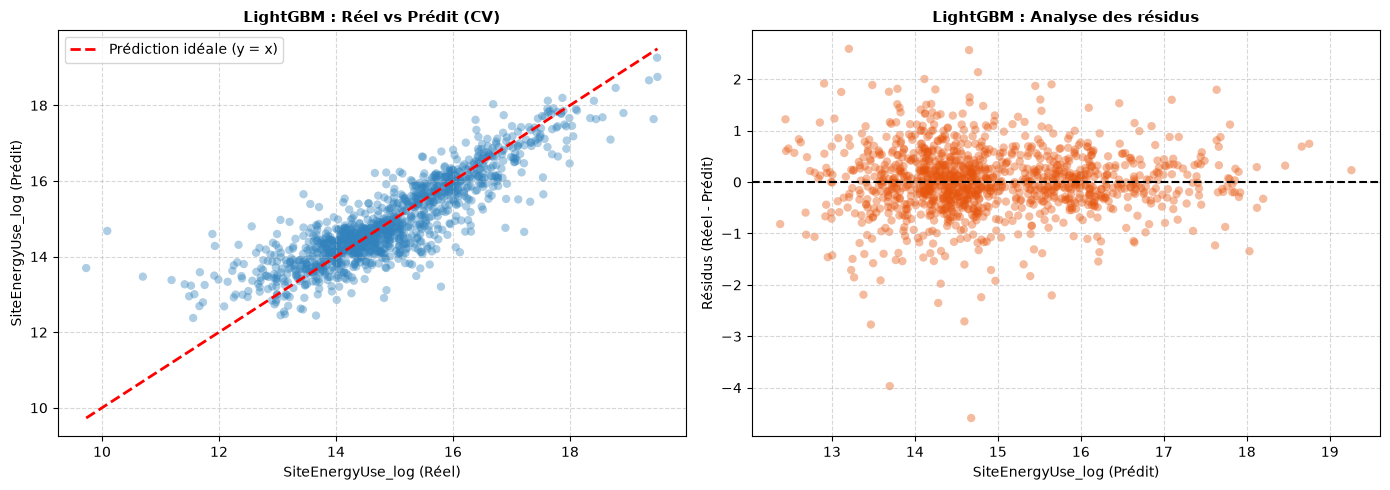

In [ ]:
# Etape 2 : Auditer le modèle vainqueur (Light LGBM) avec cross_val_predict pour analyser la présence d'erreurs SUR ENERGY

# Modèle issu de la pré-optimisation manuelle
lgb_model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.032, max_depth=4, subsample=0.76, random_state=42, num_leaves=16, min_child_samples=4, subsample_freq=1, verbose=-1, n_jobs=-1)

# Pipeline hermétique sans fuite de données
pipe_lgb_audit = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', lgb_model)
])

# Prédictions out-of-fold sur le Train brut
y_pred_cv_lgb = cross_val_predict(pipe_lgb_audit, X_train, y_train_energy, cv=cv, n_jobs=-1)
residuals_lgb = y_train_energy - y_pred_cv_lgb

# Tracé des graphiques de diagnostic
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphe 1 : Réel vs Prédit
axes[0].scatter(y_train_energy, y_pred_cv_lgb, alpha=0.4, color='#3182bd', edgecolors='none')
min_val = min(y_train_energy.min(), y_pred_cv_lgb.min())
max_val = max(y_train_energy.max(), y_pred_cv_lgb.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Prédiction idéale (y = x)')
axes[0].set_title("LightGBM : Réel vs Prédit (CV)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("SiteEnergyUse_log (Réel)")
axes[0].set_ylabel("SiteEnergyUse_log (Prédit)")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Graphe 2 : Résidus vs Prédit (Homoscédasticité et biais)
axes[1].scatter(y_pred_cv_lgb, residuals_lgb, alpha=0.4, color='#e6550d', edgecolors='none')
axes[1].axhline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title("LightGBM : Analyse des résidus", fontsize=11, fontweight='bold')
axes[1].set_xlabel("SiteEnergyUse_log (Prédit)")
axes[1].set_ylabel("Résidus (Réel - Prédit)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

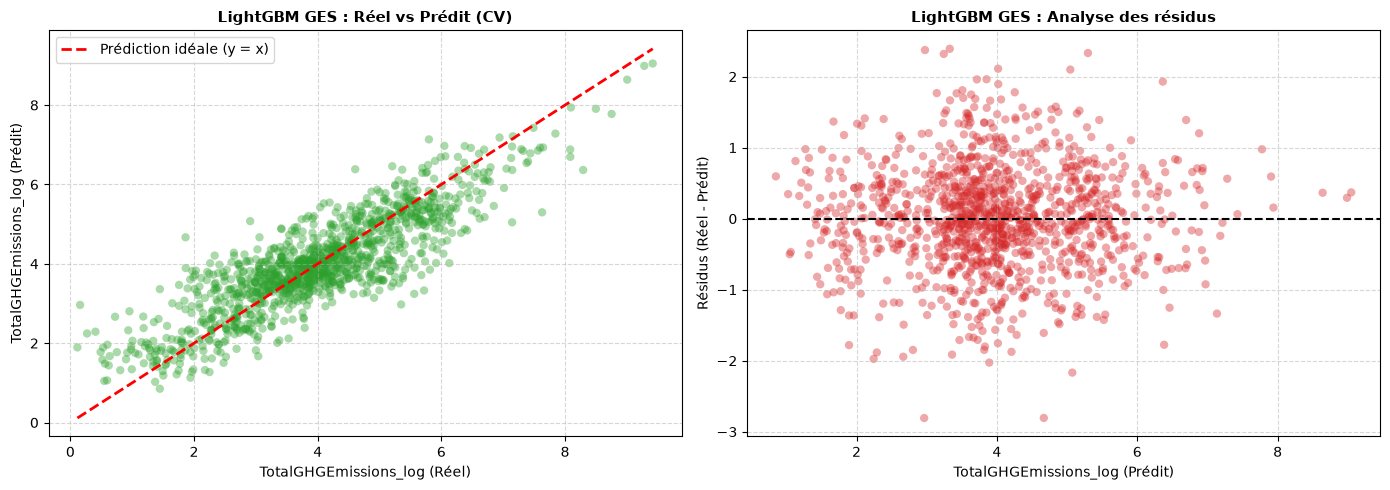

In [ ]:
# Etape 2 bis : Auditer le modèle vainqueur (Light LGBM) avec cross_val_predict pour analyser la présence d'erreurs SUR GHG

# Modèle issu de la pré-optimisation manuelle
lgbm_model_ghg = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.035, max_depth=4, subsample=0.75, random_state=42, num_leaves=15, min_child_samples=4, subsample_freq=1, verbose=-1, n_jobs=-1)

# Pipeline hermétique sans fuite de données
pipe_lgb_audit_ghg = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', lgbm_model_ghg)
])

# Prédictions out-of-fold sur le Train brut
y_pred_cv_lgbm_ghg = cross_val_predict(pipe_lgb_audit_ghg, X_train, y_train_ghg, cv=cv, n_jobs=-1)
residuals_ghg = y_train_ghg - y_pred_cv_lgbm_ghg

# Tracé des graphiques de diagnostic
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphe 1 : Valeurs réelles vs Prédictions
axes[0].scatter(y_train_ghg, y_pred_cv_lgbm_ghg, alpha=0.4, color='#2ca02c', edgecolors='none')
min_val = min(y_train_ghg.min(), y_pred_cv_lgbm_ghg.min())
max_val = max(y_train_ghg.max(), y_pred_cv_lgbm_ghg.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Prédiction idéale (y = x)')
axes[0].set_title("LightGBM GES : Réel vs Prédit (CV)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("TotalGHGEmissions_log (Réel)")
axes[0].set_ylabel("TotalGHGEmissions_log (Prédit)")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Graphe 2 : Analyse des résidus
axes[1].scatter(y_pred_cv_lgbm_ghg, residuals_ghg, alpha=0.4, color='#d62728', edgecolors='none')
axes[1].axhline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title("LightGBM GES : Analyse des résidus", fontsize=11, fontweight='bold')
axes[1].set_xlabel("TotalGHGEmissions_log (Prédit)")
axes[1].set_ylabel("Résidus (Réel - Prédit)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# code pour extraire les bâtiments dont l'erreur absolue dépasse 2 fois l'écart type (les 5% les plus mal prédits) et observer leurs caractéristiques
# SUR ENERGY

# Calcul du seuil statistique d'erreur (2 écarts-types des résidus)
std_residuals_lgbm = np.std(residuals_lgb)
outlier_threshold_lgbm = 2 * std_residuals_lgbm

# Construction du DataFrame d'audit aligné sur l'index de X_train
df_audit_lgbm = X_train.copy()
df_audit_lgbm['Reel_log'] = y_train_energy
df_audit_lgbm['Predit_log'] = y_pred_cv_lgb
df_audit_lgbm['Residu'] = residuals_lgb
df_audit_lgbm['Erreur_Absolue'] = np.abs(residuals_lgb)
df_audit_lgbm['Ratio_Reel_sur_Predit'] = np.exp(residuals_lgb) # Ratio multiplicatif sur l'échelle réelle : exp(Reel - Predit) = Réel / Prédit

# Filtrage des bâtiments atypiques (> 2 sigmas)
outliers_lgbm = df_audit_lgbm[df_audit_lgbm['Erreur_Absolue'] > outlier_threshold_lgbm].sort_values(
    by='Erreur_Absolue', ascending=False
)

print(f"Nombre total de bâtiments analysés : {len(df_audit_lgbm)}")
print(f"Bâtiments atypiques détectés (> 2σ) : {len(outliers_lgbm)} ({len(outliers_lgbm)/len(df_audit_lgbm)*100:.1f}%)")

# Sélection dynamique des colonnes informatives présentes
candidate_cols = [
    'PrimaryPropertyType', 'Neighborhood', 'PropertyGFATotal', 
    'BuildingAge', 'NumberofFloors', 'HasGas', 'HasSteam',
    'Ratio_Reel_sur_Predit', 'Residu', 'Reel_log', 'Predit_log'
]
cols_to_display = [col for col in candidate_cols if col in df_audit_lgbm.columns]

# Affichage des 5 pires prédictions
outliers_lgbm[cols_to_display].head(5).round(2)

Nombre total de bâtiments analysés : 1188
Bâtiments atypiques détectés (> 2σ) : 69 (5.8%)


,PrimaryPropertyType,Neighborhood,BuildingAge,NumberofFloors,HasGas,HasSteam,Ratio_Reel_sur_Predit,Residu,Reel_log,Predit_log
1229,Small- and Mid-Sized Office,DOWNTOWN,113,3,0,0,0.01,-4.59,10.09,14.68
2189,Other,GREATER DUWAMISH,106,3,0,0,0.02,-3.97,9.73,13.70
1295,Other,DOWNTOWN,116,3,0,0,0.06,-2.77,10.70,13.47
1045,Retail Store,GREATER DUWAMISH,63,1,1,0,0.07,-2.71,11.89,14.60
1593,Other,BALLARD,116,3,1,0,13.34,2.59,15.80,13.20


In [ ]:
# code pour extraire les bâtiments dont l'erreur absolue dépasse 2 fois l'écart type (les 5% les plus mal prédits) et observer leurs caractéristiques
# SUR GHG

# Extraction des pires prédictions (> 2 écarts-types)
std_residuals_ghg = np.std(residuals_ghg)
threshold_ghg = 2 * std_residuals_ghg

df_audit_ghg = X_train.copy()
df_audit_ghg['Reel_log'] = y_train_ghg
df_audit_ghg['Predit_log'] = y_pred_cv_lgbm_ghg
df_audit_ghg['Residu'] = residuals_ghg
df_audit_ghg['Erreur_Absolue'] = np.abs(residuals_ghg)
df_audit_ghg['Ratio_Reel_sur_Predit'] = np.exp(residuals_ghg)

outliers_ghg = df_audit_ghg[df_audit_ghg['Erreur_Absolue'] > threshold_ghg].sort_values(
    by='Erreur_Absolue', ascending=False
)

print(f"Bâtiments atypiques GES détectés (> 2σ) : {len(outliers_ghg)} ({len(outliers_ghg)/len(df_audit_ghg)*100:.1f}%)")

candidate_cols = [
    'PrimaryPropertyType', 'Neighborhood', 'PropertyGFATotal', 
    'NumberofFloors', 'HasGas', 'HasSteam', 'BuildingAge',
    'Ratio_Reel_sur_Predit', 'Residu', 'Reel_log', 'Predit_log'
]
cols_to_display = [col for col in candidate_cols if col in df_audit_ghg.columns]

outliers_ghg[cols_to_display].head(5).round(2)


Bâtiments atypiques GES détectés (> 2σ) : 64 (5.4%)


,PrimaryPropertyType,Neighborhood,NumberofFloors,HasGas,HasSteam,BuildingAge,Ratio_Reel_sur_Predit,Residu,Reel_log,Predit_log
1229,Small- and Mid-Sized Office,DOWNTOWN,3,0,0,113,0.06,-2.81,0.16,2.96
316,Distribution Center,GREATER DUWAMISH,1,1,0,56,0.06,-2.81,1.86,4.67
1593,Other,BALLARD,3,1,0,116,10.93,2.39,5.72,3.33
240,Other,NORTHEAST,5,0,0,47,10.74,2.37,5.35,2.98
119,Other,DOWNTOWN,11,1,0,12,10.30,2.33,7.63,5.30


### Analyse des résultats de l'audit 

On remarque pour l'energie et les GHG une sur estimation sur les plus faibles valeurs et une sous estimation sur les valeurs les plus importantes (on va avoir un modèle optimiste)

On remarque le batiment 1229 qui ressort en anomalie dans les 2 cibles également 3 sur 5 des other sous entendant des batiments plus inhabituels donc moins appris et compris par le modèle

On se confirme avec les résidus que la taille est très influente dans l'augmentation de l'energie
et que d'autre variables influence de manière non négligeable les GHG : le type d'energie (gas et steam) ou l'activité en plus de la taille

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Optimisation et interprétation du modèle</h3>
</div>

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

In [ ]:
# Recherche des paramètres optimaux POUR ENERGY

# Configuration de la validation croisée
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Modèle de base LightGBM
lgbm_base = lgb.LGBMRegressor(max_depth=4, subsample=0.76, subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1)

# Assemblage dans le Pipeline anti-fuite
pipeline_lgb_energy = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', lgbm_base)
])

# Grille d'hyperparamètres ciblée autour de mes paramètres empiriques
param_grid_lgb = {
    'regressor__num_leaves': [14, 15, 16],
    'regressor__min_child_samples': [3, 4, 5],
    'regressor__learning_rate': [0.028, 0.03, 0.032],
    'regressor__n_estimators': [320, 340, 360]
}

# Exécution du GridSearch
grid_search_lgb = GridSearchCV(
    estimator=pipeline_lgb_energy,
    param_grid=param_grid_lgb,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    return_train_score=True
)

# Fit strict sur X_train brut (le préprocessing est recalculé à chaque pli)
grid_search_lgb.fit(X_train, y_train_energy)

# Affichage des meilleurs réglages et conversion de la MAE en valeur positive

print(f"Meilleurs hyperparamètres (Energie) : {grid_search_lgb.best_params_}")
print(f"Meilleure MAE Val (CV) moyenne (log) : {-grid_search_lgb.best_score_:.3f}")

Meilleurs hyperparamètres (Energie) : {'regressor__learning_rate': 0.03, 'regressor__min_child_samples': 4, 'regressor__n_estimators': 340, 'regressor__num_leaves': 15}
Meilleure MAE Val (CV) moyenne (log) : 0.467


In [ ]:
# Modèle vainqueur issu du GridSearch Energy
best_lgb = grid_search_lgb.best_estimator_

# Prédictions hors-échantillon globales via cross_val_predict sur X_train brut
y_pred_log_lgb = cross_val_predict(best_lgb, X_train, y_train_energy, cv=cv, n_jobs=-1)

# Reconversion vers les unités réelles (kBtu) avec borne physique à 0
y_pred_real_lgb = np.clip(np.expm1(y_pred_log_lgb), 0, None)
y_train_energy_real = np.expm1(y_train_energy)

# Tableau récapitulatif aligné sur les métriques de predict
res_best_lgb = pd.DataFrame([{
    'Modèle': 'LightGBM Optimisé (GridSearch)',
    'R² (log)': r2_score(y_train_energy, y_pred_log_lgb),
    'MAE (log)': mean_absolute_error(y_train_energy, y_pred_log_lgb),
    'RMSE (log)': np.sqrt(mean_squared_error(y_train_energy, y_pred_log_lgb)),
    'MAE Réelle (kBtu)': mean_absolute_error(y_train_energy_real, y_pred_real_lgb)
}])

res_best_lgb.round(3)

,Modèle,R² (log),MAE (log),RMSE (log),MAE Réelle (kBtu)
0,LightGBM Optimisé (GridSearch),0.758,0.467,0.651,3278076.898


Par défaut, LightGBM quantifie l'importance par la fréquence de découpe (Split), ce qui surévalue les variables continues comme l'âge du bâtiment. Nous avons basculé sur le Gain pour trouver la vraie réduction d'impureté


Top 10 des variables les plus importantes pour l'Énergie (Gain MDI) :
                                        Feature  Importance (%)
                           PropertyGFATotal_log           67.40
                                    BuildingAge            5.49
                  PrimaryPropertyType_Warehouse            4.39
PrimaryPropertyType_Supermarket / Grocery Store            3.72
                                         HasGas            3.46
                      PrimaryPropertyType_Other            2.28
                                 NumberofFloors            2.17
      PrimaryPropertyType_Self-Storage Facility            1.87
        PrimaryPropertyType_Distribution Center            1.48
                 PrimaryPropertyType_Laboratory            1.20


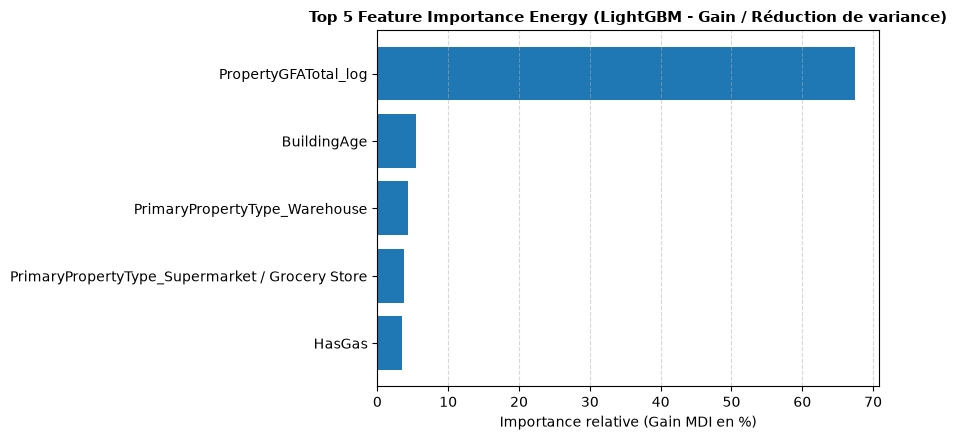

In [ ]:
# Recherche des variables les plus importantes (Feature Importance) POUR ENERGY

# Accès au modèle LightGBM et au préprocesseur fitté dans le Pipeline
lgb_regressor = best_lgb.named_steps['regressor']
preprocessor_fitted = best_lgb.named_steps['preprocessor']

# Extraction de l'importance par GAIN (réduction réelle de variance MDI)
importances_gain_energy = lgb_regressor.booster_.feature_importance(importance_type='gain')
feature_names = preprocessor_fitted.get_feature_names_out()

# Normalisation en pourcentage (somme = 100 %)
importances_gain_pct_energy = (
    importances_gain_energy / importances_gain_energy.sum()
) * 100

df_importance_energy = pd.DataFrame({
    'Feature': feature_names,
    'Importance (%)': importances_gain_pct_energy
}).sort_values(by='Importance (%)', ascending=False)

# Affichage des 10 variables les plus impactantes
print("\nTop 10 des variables les plus importantes pour l'Énergie (Gain MDI) :")
print(df_importance_energy.head(10).round(2).to_string(index=False))

# Tracé graphique horizontal des 5 variables maîtresses
top_n = 5
top_features_energy = df_importance_energy.head(top_n).sort_values(
    by='Importance (%)', ascending=True
)

plt.figure(figsize=(9, 4.5))
plt.barh(
    top_features_energy['Feature'],
    top_features_energy['Importance (%)'],
    color='#1f77b4',
    edgecolor='none'
)
plt.title(
    f"Top {top_n} Feature Importance Energy (LightGBM - Gain / Réduction de variance)",
    fontsize=11,
    fontweight='bold'
)
plt.xlabel("Importance relative (Gain MDI en %)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# Recherche des paramètres optimaux POUR GHG

# Configuration du modèle et de la validation croisée
cv = KFold(n_splits=5, shuffle=True, random_state=42)
lgbm_base_ghg = lgb.LGBMRegressor(max_depth=4, subsample=0.75, subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1)

# Assemblage hermétique dans le Pipeline
pipeline_lgb_ghg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', lgbm_base_ghg)
])

# Grille d'hyperparamètres ciblant strictement l'étape 'regressor'
param_grid_ghg = {
    'regressor__num_leaves': [14, 15, 16],
    'regressor__min_child_samples': [3, 4, 5],
    'regressor__learning_rate': [0.0355, 0.0360, 0.0365],
    'regressor__n_estimators': [270, 275, 280]
}

# Exécution du GridSearchCV sur les GES
grid_search_ghg = GridSearchCV(
    estimator=pipeline_lgb_ghg,
    param_grid=param_grid_ghg,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    return_train_score=True
)

# Fit strict sur X_train brut (préprocessing recalculé à chaque pli)
grid_search_ghg.fit(X_train, y_train_ghg)

# Modèle vainqueur (Pipeline complet) et meilleurs scores
best_lgbm_ghg = grid_search_ghg.best_estimator_
print(f"Meilleurs hyperparamètres (GES) : {grid_search_ghg.best_params_}")
print(f"Meilleure MAE Val (CV) moyenne (log) : {-grid_search_ghg.best_score_:.3f}")

Meilleurs hyperparamètres (GES) : {'regressor__learning_rate': 0.036, 'regressor__min_child_samples': 4, 'regressor__n_estimators': 275, 'regressor__num_leaves': 15}
Meilleure MAE Val (CV) moyenne (log) : 0.561


In [ ]:
# Modèle vainqueur issu du GridSearch GHG
best_lgbm_ghg = grid_search_ghg.best_estimator_

# Prédictions hors-échantillon globales via cross_val_predict sur X_train brut
y_pred_log_lgb_ghg = cross_val_predict(best_lgbm_ghg, X_train, y_train_ghg, cv=cv, n_jobs=-1)

# Reconversion vers les unités réelles (kBtu)
y_pred_real_lgb_ghg = np.clip(np.expm1(y_pred_log_lgb_ghg), 0, None)
y_train_ghg_real = np.expm1(y_train_ghg)

# Tableau récapitulatif aligné sur les métriques de predict
res_best_lgb_ghg = pd.DataFrame([{
    'Modèle': 'LightGBM Optimisé GHG (GridSearch)',
    'R² (log)': r2_score(y_train_ghg, y_pred_log_lgb_ghg),
    'MAE (log)': mean_absolute_error(y_train_ghg, y_pred_log_lgb_ghg),
    'RMSE (log)': np.sqrt(mean_squared_error(y_train_ghg, y_pred_log_lgb_ghg)),
    'MAE Réelle (kBtu)': mean_absolute_error(y_train_ghg_real, y_pred_real_lgb_ghg)
}])

res_best_lgb_ghg.round(3)

,Modèle,R² (log),MAE (log),RMSE (log),MAE Réelle (kBtu)
0,LightGBM Optimisé GHG (GridSearch),0.743,0.561,0.73,85.119



Top 10 des variables par GAIN (MDI réel - GES) :
                                        Feature  Importance (%)
                           PropertyGFATotal_log           46.23
                                         HasGas           21.29
                                    BuildingAge            5.04
                                       HasSteam            4.60
                  PrimaryPropertyType_Warehouse            3.07
PrimaryPropertyType_Supermarket / Grocery Store            2.56
                                 NumberofFloors            2.32
                   PrimaryPropertyType_Hospital            2.10
                      PrimaryPropertyType_Other            1.96
                 PrimaryPropertyType_Laboratory            1.42


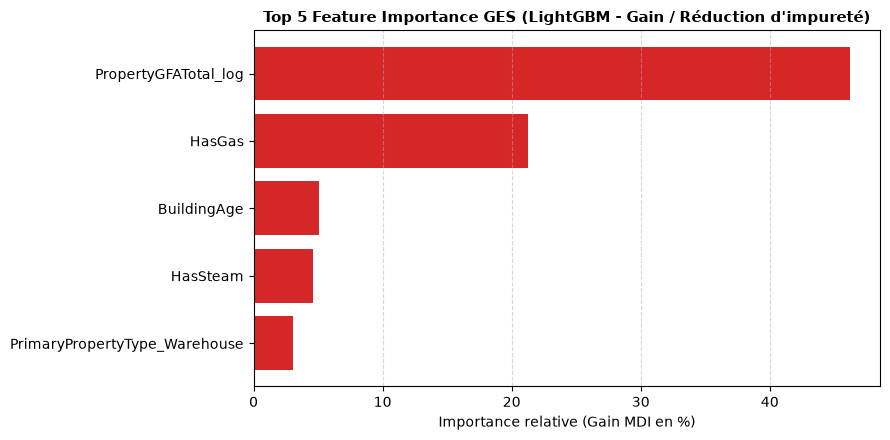

In [ ]:
# Recherche des variables les plus importantes (Feature Importance) POUR GHG

# Interprétation via la Feature Importance
# Extraction du regressor et du preprocessor optimisé dans le Pipeline
lgb_regressor_ghg = best_lgbm_ghg.named_steps['regressor']
preprocessor_fitted_ghg = best_lgbm_ghg.named_steps['preprocessor']

# Extraction de l'importance par GAIN (réduction de variance MDI) et des noms réels de colonnes
importances_gain_ghg = lgb_regressor_ghg.booster_.feature_importance(importance_type='gain')
feature_names_ghg = preprocessor_fitted_ghg.get_feature_names_out()

# Normalisation en pourcentage (somme = 100 %) comme dans Scikit-Learn
importances_gain_pct_ghg = (importances_gain_ghg / importances_gain_ghg.sum()) * 100

df_importance_ghg = pd.DataFrame({
    'Feature': feature_names_ghg,
    'Importance (%)': importances_gain_pct_ghg
}).sort_values(by='Importance (%)', ascending=False)

print("\nTop 10 des variables par GAIN (MDI réel - GES) :")
print(df_importance_ghg.head(10).round(2).to_string(index=False))

# 4. Tracé horizontal des 5 variables maîtresses
top_n = 5
top_features_ghg = df_importance_ghg.head(top_n).sort_values(
    by='Importance (%)', ascending=True
)

plt.figure(figsize=(9, 4.5))
plt.barh(
    top_features_ghg['Feature'],
    top_features_ghg['Importance (%)'],
    color='#d62728',
    edgecolor='none'
)
plt.title(
    f"Top {top_n} Feature Importance GES (LightGBM - Gain / Réduction d'impureté)",
    fontsize=11,
    fontweight='bold'
)
plt.xlabel("Importance relative (Gain MDI en %)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(36,172,189);" >
<h3 style="margin: auto; padding: 20px; color: RGB(36,172,189); ">Evaluation finale sur le jeu de test (X_test)</h3>
</div>

In [ ]:
# Evaluation finale sur le jeu de test (X_test, y_test) pour Energy et GHG

# Cibles réelles non logarithmiques du jeu de test
y_test_energy_real = np.expm1(y_test_energy)
y_test_ghg_real = np.expm1(y_test_ghg)

# Calcul des cibles réelles d'entraînement pour évaluer la MAE réelle de validation
y_train_energy_real = np.expm1(y_train_energy)
y_train_ghg_real = np.expm1(y_train_ghg)

# Prédictions hors-échantillon de VALIDATION (CV sur X_train brut)
# Calcul des prédictions out-of-fold pour obtenir les métriques de validation
y_val_pred_energy_log = cross_val_predict(best_lgb, X_train, y_train_energy, cv=cv, n_jobs=-1)
y_val_pred_ghg_log = cross_val_predict(best_lgbm_ghg, X_train, y_train_ghg, cv=cv, n_jobs=-1)

# Prédictions directes via les Pipelines optimisés (préprocessing automatique), lors de l'enregistrement du pipeline GridSearchCV on a fait un fit sur xtrain original
y_test_pred_energy_log = best_lgb.predict(X_test)
y_test_pred_ghg_log = best_lgbm_ghg.predict(X_test)

# Reconversion à l'échelle physique avec seuil inférieur à zéro
y_test_pred_energy_real = np.clip(np.expm1(y_test_pred_energy_log), 0, None)
y_test_pred_ghg_real = np.clip(np.expm1(y_test_pred_ghg_log), 0, None)

# Reconversion des prédictions de validation vers les unités physiques
y_val_pred_energy_real = np.clip(np.expm1(y_val_pred_energy_log), 0, None)
y_val_pred_ghg_real = np.clip(np.expm1(y_val_pred_ghg_log), 0, None)

# Synthèse comparative : Métriques de Validation (CV) vs Test Final
# Intégration complète des métriques demandées (R², MAE, RMSE en Validation CV et Test)
final_test_results = pd.DataFrame([
    {
        'Cible': 'Consommation Énergie (SiteEnergyUse)',
        'R² Val (CV)': r2_score(y_train_energy, y_val_pred_energy_log),
        'R² Test Final': r2_score(y_test_energy, y_test_pred_energy_log),
        'MAE Val (log)': mean_absolute_error(y_train_energy, y_val_pred_energy_log),
        'MAE Test (log)': mean_absolute_error(y_test_energy, y_test_pred_energy_log),
        'RMSE Val (log)': np.sqrt(mean_squared_error(y_train_energy, y_val_pred_energy_log)),
        'RMSE Test (log)': np.sqrt(mean_squared_error(y_test_energy, y_test_pred_energy_log)),
        'MAE Réelle Val': mean_absolute_error(y_train_energy_real, y_val_pred_energy_real),
        'MAE Réelle Test': mean_absolute_error(y_test_energy_real, y_test_pred_energy_real),
        'Unité Réelle': 'kBtu'
    },
    {
        'Cible': 'Émissions GES (TotalGHGEmissions)',
        'R² Val (CV)': r2_score(y_train_ghg, y_val_pred_ghg_log),
        'R² Test Final': r2_score(y_test_ghg, y_test_pred_ghg_log),
        'MAE Val (log)': mean_absolute_error(y_train_ghg, y_val_pred_ghg_log),
        'MAE Test (log)': mean_absolute_error(y_test_ghg, y_test_pred_ghg_log),
        'RMSE Val (log)': np.sqrt(mean_squared_error(y_train_ghg, y_val_pred_ghg_log)),
        'RMSE Test (log)': np.sqrt(mean_squared_error(y_test_ghg, y_test_pred_ghg_log)),
        'MAE Réelle Val': mean_absolute_error(y_train_ghg_real, y_val_pred_ghg_real),
        'MAE Réelle Test': mean_absolute_error(y_test_ghg_real, y_test_pred_ghg_real),
        'Unité Réelle': 'Tonnes CO2'
    }
])

display(final_test_results.round(3))

,Cible,R² Val (CV),R² Test Final,MAE Val (log),MAE Test (log),RMSE Val (log),RMSE Test (log),MAE Réelle Val,MAE Réelle Test,Unité Réelle
0,Consommation Énergie (SiteEnergyUse),0.758,0.668,0.467,0.552,0.651,0.762,3278076.898,5617366.564,kBtu
1,Émissions GES (TotalGHGEmissions),0.743,0.675,0.561,0.625,0.730,0.823,85.119,111.979,Tonnes CO2


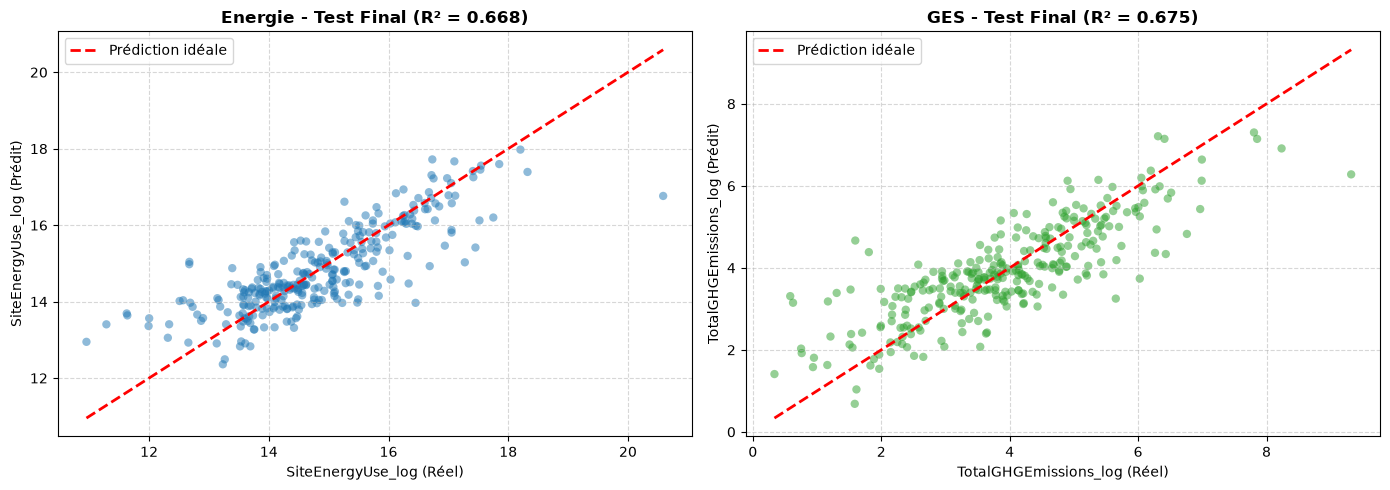

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphe Energie sur Test
axes[0].scatter(y_test_energy, y_test_pred_energy_log, alpha=0.5, color='#1f77b4', edgecolors='none')
min_e = min(y_test_energy.min(), y_test_pred_energy_log.min())
max_e = max(y_test_energy.max(), y_test_pred_energy_log.max())
axes[0].plot([min_e, max_e], [min_e, max_e], 'r--', lw=2, label='Prédiction idéale')
axes[0].set_title(f"Energie - Test Final (R² = {r2_score(y_test_energy, y_test_pred_energy_log):.3f})", fontweight='bold')
axes[0].set_xlabel("SiteEnergyUse_log (Réel)")
axes[0].set_ylabel("SiteEnergyUse_log (Prédit)")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Graphe GES sur Test
axes[1].scatter(y_test_ghg, y_test_pred_ghg_log, alpha=0.5, color='#2ca02c', edgecolors='none')
min_g = min(y_test_ghg.min(), y_test_pred_ghg_log.min())
max_g = max(y_test_ghg.max(), y_test_pred_ghg_log.max())
axes[1].plot([min_g, max_g], [min_g, max_g], 'r--', lw=2, label='Prédiction idéale')
axes[1].set_title(f"GES - Test Final (R² = {r2_score(y_test_ghg, y_test_pred_ghg_log):.3f})", fontweight='bold')
axes[1].set_xlabel("TotalGHGEmissions_log (Réel)")
axes[1].set_ylabel("TotalGHGEmissions_log (Prédit)")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()